<a href="https://colab.research.google.com/github/NanThawe/Solar-Filament-Segmentation/blob/main/Experiments_SolarFilamentSegmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#V4-G 0.34 model

In [ ]:
!pip install -q pycocotools

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/solar_filament_v4c"
)

PROJECT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(PROJECT_DIR)

/content/drive/MyDrive/solar_filament_v4c


In [ ]:
FOLD0_CHECKPOINT = (
    PROJECT_DIR / "v4c_fold0.pt"
)

assert FOLD0_CHECKPOINT.exists(), (
    f"Fold 0 checkpoint not found: "
    f"{FOLD0_CHECKPOINT}"
)

print("Fold 0 checkpoint found:")
print(FOLD0_CHECKPOINT)

Fold 0 checkpoint found:
/content/drive/MyDrive/solar_filament_v4c/v4c_fold0.pt


In [ ]:
DATA_ROOT = Path(
    "/content/drive/MyDrive/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026"
)

In [ ]:
from dataclasses import dataclass

@dataclass
class Config:

    # Resolution
    full_res: int = 2048
    work_res: int = 1024
    crop_size: int = 512

    # Cross-validation
    n_folds: int = 3
    seed: int = 42

    # V4-D
    folds_to_train: tuple = (0, 1, 2)

    model_tag: str = "v4d"
    init_tag: str = "v4c"

    # Model
    base_width: int = 24

    # Fine-tuning
    epochs: int = 8
    batch_size: int = 4
    learning_rate: float = 3e-4
    weight_decay: float = 1e-4

    crops_per_image: int = 6

    # Crop sampling
    foreground_crop_prob: float = 0.60
    hard_negative_crop_prob: float = 0.20
    # remaining 0.20 = random

    # Loss
    dice_weight: float = 0.5
    cldice_weight: float = 0.20
    cldice_iters: int = 10
    spine_weight: float = 0.30

    # Physics channels
    disk_fraction: float = 0.985
    local_mean_sigma: float = 16.0
    local_std_sigma: float = 32.0
    ridge_sigmas: tuple = (1.5, 3.0, 6.0)

    # Early stopping
    patience: int = 3

    # Postprocessing
    min_area_default: int = 30

    # Inference
    use_tta: bool = False


CFG = Config()

assert (
    CFG.foreground_crop_prob
    + CFG.hard_negative_crop_prob
    <= 1.0
)

CFG

Config(full_res=2048, work_res=1024, crop_size=512, n_folds=3, seed=42, folds_to_train=(0, 1, 2), model_tag='v4d', init_tag='v4c', base_width=24, epochs=8, batch_size=4, learning_rate=0.0003, weight_decay=0.0001, crops_per_image=6, foreground_crop_prob=0.6, hard_negative_crop_prob=0.2, dice_weight=0.5, cldice_weight=0.2, cldice_iters=10, spine_weight=0.3, disk_fraction=0.985, local_mean_sigma=16.0, local_std_sigma=32.0, ridge_sigmas=(1.5, 3.0, 6.0), patience=3, min_area_default=30, use_tta=False)

Imports

In [ ]:
import os
import gc
import json
import random
import shutil

from collections import defaultdict
from functools import lru_cache

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import ndimage as ndi

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

from pycocotools import mask as mask_utils

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    Dataset,
    DataLoader
)

from tqdm.auto import tqdm


def seed_everything(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything(CFG.seed)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print(
        torch.cuda.get_device_name(0)
    )

Device: cuda
Tesla T4


In [ ]:
ANN_PATH = (
    DATA_ROOT
    / "train"
    / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

TRAIN_IMAGE_DIR = (
    DATA_ROOT
    / "train"
    / "train_images"
)

TEST_IMAGE_DIR = (
    DATA_ROOT
    / "test"
    / "test_images"
)


assert ANN_PATH.exists(), ANN_PATH
assert TRAIN_IMAGE_DIR.exists(), TRAIN_IMAGE_DIR
assert TEST_IMAGE_DIR.exists(), TEST_IMAGE_DIR


print("Annotations:", ANN_PATH)
print("Train:", TRAIN_IMAGE_DIR)
print("Test:", TEST_IMAGE_DIR)

Annotations: /content/drive/MyDrive/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json
Train: /content/drive/MyDrive/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/train_images
Test: /content/drive/MyDrive/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images


In [ ]:
with open(ANN_PATH, "r") as f:
    coco = json.load(f)


annotations_by_record = defaultdict(list)

for ann in coco["annotations"]:
    annotations_by_record[
        ann["image_id"]
    ].append(ann)


observations = {}

for img in coco["images"]:

    stem = Path(
        img["file_name"]
    ).stem

    if stem not in observations:

        observations[stem] = {
            "stem": stem,
            "file_name":
                img["file_name"],
            "records": [],
            "station":
                stem[-2:]
        }

    observations[
        stem
    ]["records"].append(
        img["id"]
    )


stems = sorted(
    observations.keys()
)


print(
    "Annotation records:",
    len(coco["images"])
)

print(
    "Physical observations:",
    len(stems)
)

print(
    "Instances:",
    len(coco["annotations"])
)

Annotation records: 1154
Physical observations: 707
Instances: 8199


Rasterization

In [ ]:
def scale_polygon(
    polygon,
    size,
    full_size=2048
):

    scale = size / full_size

    return (
        np.asarray(
            polygon,
            dtype=np.float32
        )
        * scale
    ).tolist()

In [ ]:
def annotations_to_union_mask(
    annotations,
    size
):

    mask = np.zeros(
        (size, size),
        dtype=np.uint8
    )

    for ann in annotations:

        segmentation = ann[
            "segmentation"
        ]

        scaled = [
            scale_polygon(
                polygon,
                size
            )
            for polygon
            in segmentation
        ]

        rles = (
            mask_utils.frPyObjects(
                scaled,
                size,
                size
            )
        )

        rle = mask_utils.merge(
            rles
        )

        mask |= (
            mask_utils.decode(
                rle
            )
            .astype(np.uint8)
        )

    return mask

Soft multi-annotator target

In [ ]:
def build_soft_target(
    stem,
    size
):

    records = observations[
        stem
    ]["records"]

    target = np.zeros(
        (size, size),
        dtype=np.float32
    )

    for record_id in records:

        target += (
            annotations_to_union_mask(
                annotations_by_record[
                    record_id
                ],
                size
            )
        )

    target /= max(
        len(records),
        1
    )

    return target

Spine Target

In [ ]:
def annotation_spine_mask(
    annotations,
    size,
    thickness=3
):

    mask = np.zeros(
        (size, size),
        dtype=np.uint8
    )

    scale = size / CFG.full_res

    for ann in annotations:

        spine = ann.get(
            "spine"
        )

        if (
            spine is None
            or len(spine) < 4
        ):
            continue

        points = (
            np.asarray(
                spine,
                dtype=np.float32
            )
            .reshape(-1, 2)
        )

        points *= scale

        points = np.round(
            points
        ).astype(np.int32)

        cv2.polylines(
            mask,
            [points],
            isClosed=False,
            color=1,
            thickness=thickness
        )

    return mask

In [ ]:
def build_spine_target(
    stem,
    size
):

    records = observations[
        stem
    ]["records"]

    target = np.zeros(
        (size, size),
        dtype=np.float32
    )

    for record_id in records:

        target += (
            annotation_spine_mask(
                annotations_by_record[
                    record_id
                ],
                size
            )
        )

    target /= max(
        len(records),
        1
    )

    return target

Solar disk fitting

In [ ]:
def fit_solar_disk(image):

    blurred = cv2.GaussianBlur(
        image,
        (0, 0),
        3
    )

    _, binary = cv2.threshold(
        blurred,
        0,
        255,
        cv2.THRESH_BINARY
        + cv2.THRESH_OTSU
    )

    n, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            (binary > 0).astype(
                np.uint8
            )
        )
    )

    if n < 2:

        h, w = image.shape

        return (
            w / 2,
            h / 2,
            min(h, w) * 0.45
        )

    component = (
        1
        + np.argmax(
            stats[
                1:,
                cv2.CC_STAT_AREA
            ]
        )
    )

    disk = (
        labels
        == component
    ).astype(np.uint8)

    contours, _ = cv2.findContours(
        disk,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_NONE
    )

    contour = max(
        contours,
        key=cv2.contourArea
    )

    (cx, cy), radius = (
        cv2.minEnclosingCircle(
            contour
        )
    )

    return (
        float(cx),
        float(cy),
        float(radius)
    )

Radius map

In [ ]:
def make_radius_map(
    shape,
    cx,
    cy,
    radius
):

    yy, xx = np.mgrid[
        :shape[0],
        :shape[1]
    ]

    r = np.hypot(
        xx - cx,
        yy - cy
    )

    return (
        r / radius
    ).astype(
        np.float32
    )

Radial normalization

In [ ]:
def radial_profile(
    image,
    radius_map,
    disk_mask,
    bins=100
):

    edges = np.linspace(
        0,
        1,
        bins + 1
    )

    indices = np.clip(
        np.digitize(
            radius_map[
                disk_mask
            ],
            edges
        ) - 1,
        0,
        bins - 1
    )

    values = image[
        disk_mask
    ].astype(np.float32)

    profile = np.zeros(
        bins,
        dtype=np.float32
    )

    centres = (
        edges[:-1]
        + edges[1:]
    ) / 2

    for i in range(bins):

        x = values[
            indices == i
        ]

        if len(x):
            profile[i] = np.median(x)
        else:
            profile[i] = np.nan

    good = ~np.isnan(
        profile
    )

    profile = np.interp(
        centres,
        centres[good],
        profile[good]
    )

    return np.interp(
        radius_map,
        centres,
        profile
    ).astype(np.float32)

Normalized Gaussian blur

In [ ]:
def normalized_blur(
    image,
    support,
    sigma
):

    numerator = (
        cv2.GaussianBlur(
            image * support,
            (0, 0),
            sigma
        )
    )

    denominator = (
        cv2.GaussianBlur(
            support,
            (0, 0),
            sigma
        )
    )

    return (
        numerator
        / np.maximum(
            denominator,
            1e-3
        )
    )

Multi-scale dark-ridge feature

In [ ]:
def gaussian_kernels(
    sigma
):

    radius = int(
        np.ceil(
            4 * sigma
        )
    )

    x = np.arange(
        -radius,
        radius + 1,
        dtype=np.float32
    )

    g = np.exp(
        -(x ** 2)
        / (2 * sigma ** 2)
    )

    g /= g.sum()

    g1 = (
        -x
        / sigma ** 2
        * g
    )

    g2 = (
        (
            x ** 2
            / sigma ** 4
        )
        -
        (
            1
            / sigma ** 2
        )
    ) * g

    return g, g1, g2

In [ ]:
def dark_ridge_response(
    image,
    sigmas
):

    ridge = np.zeros_like(
        image,
        dtype=np.float32
    )

    for sigma in sigmas:

        g, g1, g2 = (
            gaussian_kernels(
                sigma
            )
        )

        ixx = cv2.sepFilter2D(
            image,
            cv2.CV_32F,
            g2,
            g
        )

        iyy = cv2.sepFilter2D(
            image,
            cv2.CV_32F,
            g,
            g2
        )

        ixy = cv2.sepFilter2D(
            image,
            cv2.CV_32F,
            g1,
            g1
        )

        trace = (
            0.5
            * (ixx + iyy)
        )

        discriminant = np.sqrt(
            np.maximum(
                0.25
                * (ixx - iyy) ** 2
                + ixy ** 2,
                0
            )
        )

        lambda_max = (
            sigma ** 2
            * (
                trace
                + discriminant
            )
        )

        ridge = np.maximum(
            ridge,
            np.maximum(
                lambda_max,
                0
            )
        )

    return ridge

In [ ]:
def build_input_channels(
    image_full
):

    W = CFG.work_res

    image = cv2.resize(
        image_full,
        (W, W),
        interpolation=cv2.INTER_AREA
    )

    cx, cy, radius = (
        fit_solar_disk(
            image
        )
    )

    radius_map = (
        make_radius_map(
            image.shape,
            cx,
            cy,
            radius
        )
    )

    disk = (
        radius_map
        < CFG.disk_fraction
    )

    profile = radial_profile(
        image,
        radius_map,
        disk
    )

    flat = (
        image.astype(np.float32)
        /
        np.maximum(
            profile,
            1
        )
    )

    flat[
        ~disk
    ] = 1

    support = disk.astype(
        np.float32
    )

    local_mean = normalized_blur(
        flat,
        support,
        CFG.local_mean_sigma
    )

    difference = (
        flat
        - local_mean
    ) * support

    local_std = np.sqrt(
        np.maximum(
            normalized_blur(
                difference ** 2,
                support,
                CFG.local_std_sigma
            ),
            1e-8
        )
    )

    zscore = (
        difference
        / np.maximum(
            local_std,
            0.02
        )
    )

    ridge = dark_ridge_response(
        flat,
        CFG.ridge_sigmas
    )

    ridge *= support

    scale = (
        np.median(
            ridge[disk]
        )
        + 1e-6
    )

    ridge = np.log1p(
        ridge
        / (4 * scale)
    )

    channel_0 = np.clip(
        (flat - 1) / 0.25,
        -3,
        3
    )

    channel_1 = np.clip(
        zscore,
        -4,
        4
    )

    channel_2 = np.clip(
        ridge,
        0,
        4
    )

    channels = np.stack(
        [
            channel_0,
            channel_1,
            channel_2
        ]
    )

    channels *= (
        disk[None]
    )

    return (
        channels.astype(
            np.float16
        ),
        disk,
        (cx, cy, radius)
    )

Visual sanity check

In [ ]:
def find_train_image(
    stem
):

    for ext in [
        ".jpg",
        ".jpeg",
        ".png"
    ]:

        path = (
            TRAIN_IMAGE_DIR
            / f"{stem}{ext}"
        )

        if path.exists():
            return path

    raise FileNotFoundError(
        stem
    )

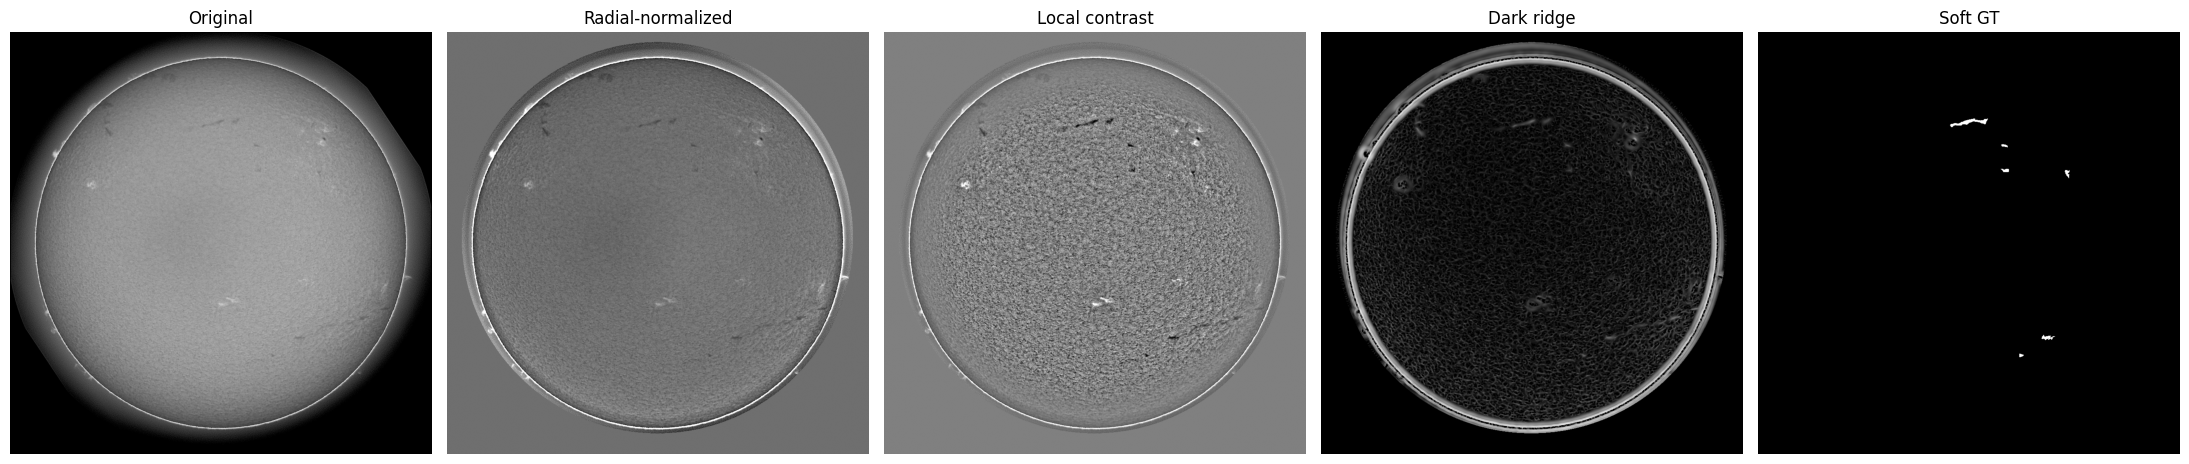

In [ ]:
sample_stem = stems[0]

sample_image = cv2.imread(
    str(
        find_train_image(
            sample_stem
        )
    ),
    cv2.IMREAD_GRAYSCALE
)

channels, disk, _ = (
    build_input_channels(
        sample_image
    )
)

soft = build_soft_target(
    sample_stem,
    CFG.work_res
)

spine = build_spine_target(
    sample_stem,
    CFG.work_res
)


fig, axes = plt.subplots(
    1,
    5,
    figsize=(22, 5)
)

axes[0].imshow(
    sample_image,
    cmap="gray"
)

axes[0].set_title(
    "Original"
)

axes[1].imshow(
    channels[0],
    cmap="gray"
)

axes[1].set_title(
    "Radial-normalized"
)

axes[2].imshow(
    channels[1],
    cmap="gray"
)

axes[2].set_title(
    "Local contrast"
)

axes[3].imshow(
    channels[2],
    cmap="gray"
)

axes[3].set_title(
    "Dark ridge"
)

axes[4].imshow(
    soft,
    cmap="gray"
)

axes[4].set_title(
    "Soft GT"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Cache preprocessing

In [ ]:
CACHE_DIR = Path(
    "/content/v4c_cache"
)

CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [ ]:
def build_cache_for_stem(
    stem
):

    output_path = (
        CACHE_DIR
        / f"{stem}.npz"
    )

    if output_path.exists():
        return

    path = find_train_image(
        stem
    )

    image = cv2.imread(
        str(path),
        cv2.IMREAD_GRAYSCALE
    )

    channels, disk, geometry = (
        build_input_channels(
            image
        )
    )

    soft = build_soft_target(
        stem,
        CFG.work_res
    )

    spine = build_spine_target(
        stem,
        CFG.work_res
    )

    foreground = np.argwhere(
        soft > 0.25
    )

    np.savez(
        output_path,

        channels=channels,

        soft=(
            soft * 255
        ).astype(np.uint8),

        spine=(
            spine * 255
        ).astype(np.uint8),

        disk=disk.astype(
            np.uint8
        ),

        foreground=foreground.astype(
            np.int16
        )
    )

In [ ]:
for stem in tqdm(stems):

    build_cache_for_stem(
        stem
    )

  0%|          | 0/707 [00:00<?, ?it/s]

Assign folds correctly

In [ ]:
stem_df = pd.DataFrame({
    "stem": stems,
    "station": [
        observations[s][
            "station"
        ]
        for s in stems
    ]
})


stem_df["fold"] = -1


splitter = StratifiedKFold(
    n_splits=CFG.n_folds,
    shuffle=True,
    random_state=CFG.seed
)


for fold, (_, val_idx) in enumerate(
    splitter.split(
        stem_df,
        stem_df["station"]
    )
):

    stem_df.loc[
        val_idx,
        "fold"
    ] = fold


display(
    pd.crosstab(
        stem_df["station"],
        stem_df["fold"]
    )
)

fold,0,1,2
station,,,
Bh,39,40,39
Ch,42,42,41
Lh,42,42,43
Mh,42,42,41
Th,37,36,37
Uh,34,34,34


In [ ]:
@lru_cache(
    maxsize=16
)
def load_cache(
    stem
):

    data = np.load(
        CACHE_DIR
        / f"{stem}.npz"
    )

    return {
        key: data[key]
        for key in data.files
    }

In [ ]:
def sample_hard_negative_center(
    channels,
    soft,
    disk,
    attempts=80
):
    """
    Find dark/ridge-like solar structure that is
    not close to an annotated filament.
    """

    H, W = soft.shape
    exclusion_radius = 20

    for _ in range(attempts):

        cy = random.randint(
            exclusion_radius,
            H - exclusion_radius - 1
        )

        cx = random.randint(
            exclusion_radius,
            W - exclusion_radius - 1
        )

        if not disk[cy, cx]:
            continue

        # Avoid labelled filament boundaries
        local_gt = soft[
            cy-exclusion_radius:
            cy+exclusion_radius+1,

            cx-exclusion_radius:
            cx+exclusion_radius+1
        ]

        if local_gt.max() > 0.05:
            continue

        intensity = float(
            channels[0, cy, cx]
        )

        contrast = float(
            channels[1, cy, cx]
        )

        ridge = float(
            channels[2, cy, cx]
        )

        # Filament-like appearance,
        # but no GT filament here
        looks_difficult = (
            intensity < -0.30
            or contrast < -0.80
            or ridge > 0.30
        )

        if looks_difficult:
            return cy, cx

    return None

In [ ]:
class FilamentCropDataset(
    Dataset
):

    def __init__(
        self,
        stems,
        training=True
    ):

        self.stems = list(
            stems
        )

        self.training = training

        self.length = (
            len(self.stems)
            * CFG.crops_per_image
        )

    def __len__(self):
        return self.length

    def __getitem__(
        self,
        index
    ):

        stem = self.stems[
            index
            % len(self.stems)
        ]

        data = load_cache(
            stem
        )

        channels = data[
            "channels"
        ]

        soft = data[
            "soft"
        ].astype(
            np.float32
        ) / 255

        spine = data[
            "spine"
        ].astype(
            np.float32
        ) / 255

        disk = data[
            "disk"
        ].astype(bool)

        foreground = data[
            "foreground"
        ]

        W = CFG.work_res
        C = CFG.crop_size

        # Initialize sample_type unconditionally first
        sample_type = (
            random.random()
            if self.training
            else 1.0
        )

        # ---------------------------------
        # 60% FILAMENT-CENTRED
        # ---------------------------------

        if (
            self.training
            and len(foreground) > 0
            and sample_type
            < CFG.foreground_crop_prob
        ):

            cy, cx = foreground[
                random.randrange(
                    len(foreground)
                )
            ]

            y0 = np.clip(
                cy
                - C // 2
                + random.randint(
                    -C // 4,
                    C // 4
                ),
                0,
                W - C
            )

            x0 = np.clip(
                cx
                - C // 2
                + random.randint(
                    -C // 4,
                    C // 4
                ),
                0,
                W - C
            )

        # ---------------------------------
        # 20% HARD NEGATIVE
        # ---------------------------------

        elif (
            self.training
            and sample_type
            <
            CFG.foreground_crop_prob
            +
            CFG.hard_negative_crop_prob
        ):

            centre = (
                sample_hard_negative_center(
                    channels,
                    soft,
                    disk
                )
            )

            if centre is not None:

                cy, cx = centre

                y0 = np.clip(
                    cy
                    - C // 2
                    + random.randint(
                        -C // 8,
                        C // 8
                    ),
                    0,
                    W - C
                )

                x0 = np.clip(
                    cx
                    - C // 2
                    + random.randint(
                        -C // 8,
                        C // 8
                    ),
                    0,
                    W - C
                )

            else:

                y0 = random.randint(
                    0,
                    W - C
                )

                x0 = random.randint(
                    0,
                    W - C
                )

        # ---------------------------------
        # 20% RANDOM
        # ---------------------------------

        else:

            y0 = random.randint(
                0,
                W - C
            )

            x0 = random.randint(
                0,
                W - C
            )

        y0 = int(y0)
        x0 = int(x0)

        image = channels[
            :,
            y0:y0+C,
            x0:x0+C
        ].astype(
            np.float32
        )

        mask = soft[
            y0:y0+C,
            x0:x0+C
        ]

        spine_mask = spine[
            y0:y0+C,
            x0:x0+C
        ]

        valid = disk[
            y0:y0+C,
            x0:x0+C
        ].astype(
            np.float32
        )

        if self.training:

            k = random.randint(
                0,
                3
            )

            image = np.rot90(
                image,
                k,
                axes=(1, 2)
            ).copy()

            mask = np.rot90(
                mask,
                k
            ).copy()

            spine_mask = np.rot90(
                spine_mask,
                k
            ).copy()

            valid = np.rot90(
                valid,
                k
            ).copy()

            if random.random() < 0.5:

                image = image[
                    :,
                    :,
                    ::-1
                ].copy()

                mask = mask[
                    :,
                    ::-1
                ].copy()

                spine_mask = (
                    spine_mask[
                        :,
                        ::-1
                    ].copy()
                )

                valid = valid[
                    :,
                    ::-1
                ].copy()

        return {
            "image":
                torch.from_numpy(
                    image
                ),

            "mask":
                torch.from_numpy(
                    mask[None]
                ),

            "spine":
                torch.from_numpy(
                    spine_mask[None]
                ),

            "valid":
                torch.from_numpy(
                    valid[None]
                )
        }

In [ ]:
def soft_erode(x):

    p1 = -F.max_pool2d(
        -x,
        kernel_size=(3, 1),
        stride=1,
        padding=(1, 0)
    )

    p2 = -F.max_pool2d(
        -x,
        kernel_size=(1, 3),
        stride=1,
        padding=(0, 1)
    )

    return torch.minimum(
        p1,
        p2
    )


def soft_dilate(x):

    return F.max_pool2d(
        x,
        kernel_size=3,
        stride=1,
        padding=1
    )


def soft_open(x):

    return soft_dilate(
        soft_erode(x)
    )


def soft_skeletonize(
    x,
    iterations=10
):

    x = torch.clamp(
        x,
        0,
        1
    )

    opened = soft_open(x)

    skeleton = F.relu(
        x - opened
    )

    for _ in range(
        iterations
    ):

        x = soft_erode(x)

        opened = soft_open(x)

        delta = F.relu(
            x - opened
        )

        skeleton = (
            skeleton
            +
            F.relu(
                delta
                - skeleton * delta
            )
        )

    return skeleton


def soft_cldice_loss(
    logits,
    target,
    valid,
    eps=1e-6
):

    probability = (
        torch.sigmoid(
            logits
        )
        * valid
    )

    target = (
        target
        * valid
    )

    pred_skeleton = (
        soft_skeletonize(
            probability,
            CFG.cldice_iters
        )
        * valid
    )

    target_skeleton = (
        soft_skeletonize(
            target,
            CFG.cldice_iters
        )
        * valid
    )

    topology_precision = (
        (
            pred_skeleton
            * target
        ).sum()
        /
        (
            pred_skeleton.sum()
            + eps
        )
    )

    topology_sensitivity = (
        (
            target_skeleton
            * probability
        ).sum()
        /
        (
            target_skeleton.sum()
            + eps
        )
    )

    cldice = (
        2
        * topology_precision
        * topology_sensitivity
        /
        (
            topology_precision
            + topology_sensitivity
            + eps
        )
    )

    return 1 - cldice

Group Norm Helper

In [ ]:
def group_norm(
    channels
):

    possible = [
        g
        for g in range(
            1,
            min(
                8,
                channels
            ) + 1
        )
        if channels % g == 0
    ]

    groups = max(
        possible
    )

    return nn.GroupNorm(
        groups,
        channels
    )

Model Building

In [ ]:
# MulitRes Model
class ConvGNAct(
    nn.Module
):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            group_norm(
                out_channels
            ),

            nn.GELU()
        )

    def forward(
        self,
        x
    ):

        return self.block(x)

In [ ]:
class MultiResBlock(
    nn.Module
):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()

        c1 = max(
            out_channels // 6,
            1
        )

        c2 = max(
            out_channels // 3,
            1
        )

        c3 = (
            out_channels
            - c1
            - c2
        )

        self.path1 = ConvGNAct(
            in_channels,
            c1
        )

        self.path2 = ConvGNAct(
            c1,
            c2
        )

        self.path3 = ConvGNAct(
            c2,
            c3
        )

        self.residual = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=1,
            bias=False
        )

        self.norm = group_norm(
            out_channels
        )

    def forward(
        self,
        x
    ):

        p1 = self.path1(x)

        p2 = self.path2(
            p1
        )

        p3 = self.path3(
            p2
        )

        multi = torch.cat(
            [
                p1,
                p2,
                p3
            ],
            dim=1
        )

        residual = (
            self.residual(x)
        )

        return F.gelu(
            self.norm(
                multi
                + residual
            )
        )

In [ ]:
class AttentionGate(
    nn.Module
):

    def __init__(
        self,
        skip_channels,
        gate_channels
    ):

        super().__init__()

        intermediate = max(
            skip_channels // 2,
            8
        )

        self.skip_projection = (
            nn.Conv2d(
                skip_channels,
                intermediate,
                1
            )
        )

        self.gate_projection = (
            nn.Conv2d(
                gate_channels,
                intermediate,
                1
            )
        )

        self.attention = (
            nn.Conv2d(
                intermediate,
                1,
                1
            )
        )

    def forward(
        self,
        skip,
        gate
    ):

        attention = (
            self.skip_projection(
                skip
            )
            +
            self.gate_projection(
                gate
            )
        )

        attention = F.gelu(
            attention
        )

        attention = torch.sigmoid(
            self.attention(
                attention
            )
        )

        return (
            skip
            * attention
        )

In [ ]:
class MultiResAttentionUNet(
    nn.Module
):

    def __init__(
        self,
        in_channels=3,
        base=24
    ):

        super().__init__()

        widths = [
            base,
            base * 2,
            base * 4,
            base * 8,
            base * 16
        ]

        self.enc1 = MultiResBlock(
            in_channels,
            widths[0]
        )

        self.enc2 = MultiResBlock(
            widths[0],
            widths[1]
        )

        self.enc3 = MultiResBlock(
            widths[1],
            widths[2]
        )

        self.enc4 = MultiResBlock(
            widths[2],
            widths[3]
        )

        self.bridge = MultiResBlock(
            widths[3],
            widths[4]
        )

        self.pool = nn.MaxPool2d(
            2
        )

        self.up4 = nn.Conv2d(
            widths[4],
            widths[3],
            1
        )

        self.att4 = AttentionGate(
            widths[3],
            widths[3]
        )

        self.dec4 = MultiResBlock(
            widths[3] * 2,
            widths[3]
        )

        self.up3 = nn.Conv2d(
            widths[3],
            widths[2],
            1
        )

        self.att3 = AttentionGate(
            widths[2],
            widths[2]
        )

        self.dec3 = MultiResBlock(
            widths[2] * 2,
            widths[2]
        )

        self.up2 = nn.Conv2d(
            widths[2],
            widths[1],
            1
        )

        self.att2 = AttentionGate(
            widths[1],
            widths[1]
        )

        self.dec2 = MultiResBlock(
            widths[1] * 2,
            widths[1]
        )

        self.up1 = nn.Conv2d(
            widths[1],
            widths[0],
            1
        )

        self.att1 = AttentionGate(
            widths[0],
            widths[0]
        )

        self.dec1 = MultiResBlock(
            widths[0] * 2,
            widths[0]
        )

        # Main semantic head
        self.mask_head = nn.Conv2d(
            widths[0],
            1,
            1
        )

        # Auxiliary topology/spine head
        self.spine_head = nn.Conv2d(
            widths[0],
            1,
            1
        )

    def upsample(
        self,
        x,
        target
    ):

        return F.interpolate(
            x,
            size=target.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

    def forward(
        self,
        x
    ):

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        e4 = self.enc4(
            self.pool(e3)
        )

        bridge = self.bridge(
            self.pool(e4)
        )

        d4 = self.upsample(
            bridge,
            e4
        )

        d4 = self.up4(d4)

        s4 = self.att4(
            e4,
            d4
        )

        d4 = self.dec4(
            torch.cat(
                [d4, s4],
                dim=1
            )
        )

        d3 = self.upsample(
            d4,
            e3
        )

        d3 = self.up3(d3)

        s3 = self.att3(
            e3,
            d3
        )

        d3 = self.dec3(
            torch.cat(
                [d3, s3],
                dim=1
            )
        )

        d2 = self.upsample(
            d3,
            e2
        )

        d2 = self.up2(d2)

        s2 = self.att2(
            e2,
            d2
        )

        d2 = self.dec2(
            torch.cat(
                [d2, s2],
                dim=1
            )
        )

        d1 = self.upsample(
            d2,
            e1
        )

        d1 = self.up1(d1)

        s1 = self.att1(
            e1,
            d1
        )

        d1 = self.dec1(
            torch.cat(
                [d1, s1],
                dim=1
            )
        )

        return {
            "mask":
                self.mask_head(d1),

            "spine":
                self.spine_head(d1)
        }

In [ ]:
model = (
    MultiResAttentionUNet(
        in_channels=3,
        base=CFG.base_width
    )
    .to(DEVICE)
)


with torch.no_grad():

    test_tensor = torch.randn(
        1,
        3,
        CFG.crop_size,
        CFG.crop_size,
        device=DEVICE
    )

    output = model(
        test_tensor
    )


print(
    output["mask"].shape
)

print(
    output["spine"].shape
)

print(
    "Parameters:",
    sum(
        p.numel()
        for p in model.parameters()
    ) / 1e6,
    "M"
)

torch.Size([1, 1, 512, 512])
torch.Size([1, 1, 512, 512])
Parameters: 1.132782 M


Loss function

In [ ]:
def masked_bce(
    logits,
    target,
    valid
):

    loss = (
        F.binary_cross_entropy_with_logits(
            logits,
            target,
            reduction="none"
        )
    )

    return (
        (loss * valid).sum()
        /
        valid.sum().clamp_min(1)
    )

In [ ]:
def soft_dice_loss(
    logits,
    target,
    valid,
    eps=1.0
):

    probability = (
        torch.sigmoid(
            logits
        )
        * valid
    )

    target = (
        target
        * valid
    )

    numerator = (
        2
        * (
            probability
            * target
        ).sum()
        + eps
    )

    denominator = (
        probability.sum()
        + target.sum()
        + eps
    )

    return (
        1
        - numerator
        / denominator
    )

In [ ]:
def compute_loss(
    output,
    target,
    spine,
    valid,
    use_topology=True
):

    segmentation_loss = (
        masked_bce(
            output["mask"],
            target,
            valid
        )

        +

        CFG.dice_weight
        * soft_dice_loss(
            output["mask"],
            target,
            valid
        )
    )

    if use_topology:

        topology_loss = (
            soft_cldice_loss(
                output["mask"],
                target,
                valid
            )
        )

    else:

        topology_loss = (
            output["mask"].new_tensor(
                0.0
            )
        )

    mask_loss = (
        segmentation_loss
        +
        CFG.cldice_weight
        * topology_loss
    )

    spine_loss = (
        0.5
        * masked_bce(
            output["spine"],
            spine,
            valid
        )

        +

        soft_dice_loss(
            output["spine"],
            spine,
            valid
        )
    )

    total = (
        mask_loss
        +
        CFG.spine_weight
        * spine_loss
    )

    return (
        total,
        mask_loss,
        spine_loss
    )

In [ ]:
@torch.no_grad()
def predict_probability(
    model,
    stem
):

    data = load_cache(
        stem
    )

    image = torch.from_numpy(
        data["channels"].astype(
            np.float32
        )
    )[None].to(DEVICE)

    model.eval()

    logits = model(
        image
    )["mask"]

    probability = torch.sigmoid(
        logits
    )[0, 0]

    return (
        probability
        .cpu()
        .numpy()
    )

Validation function

In [ ]:
@torch.no_grad()
def validate_model(
    model,
    val_stems
):

    model.eval()

    losses = []
    dice_scores = []

    for stem in tqdm(
        val_stems,
        leave=False
    ):

        data = load_cache(
            stem
        )

        image = torch.from_numpy(
            data["channels"]
            .astype(np.float32)
        )[None].to(DEVICE)

        target = torch.from_numpy(
            data["soft"]
            .astype(np.float32)
            / 255
        )[None, None].to(DEVICE)

        spine = torch.from_numpy(
            data["spine"]
            .astype(np.float32)
            / 255
        )[None, None].to(DEVICE)

        valid = torch.from_numpy(
            data["disk"]
            .astype(np.float32)
        )[None, None].to(DEVICE)

        output = model(
            image
        )

        loss, _, _ = compute_loss(
            output,
            target,
            spine,
            valid,
            use_topology=False
        )

        probability = (
            torch.sigmoid(
                output["mask"]
            )
            * valid
        )

        numerator = (
            2
            * (
                probability
                * target
            ).sum()
        )

        denominator = (
            probability.sum()
            + target.sum()
            + 1e-6
        )

        dice = (
            numerator
            / denominator
        )

        losses.append(
            float(loss)
        )

        dice_scores.append(
            float(dice)
        )

    return {
        "loss":
            np.mean(losses),

        "soft_dice":
            np.mean(
                dice_scores
            )
    }

Training function

In [ ]:
def train_fold(fold):

    seed_everything(
        CFG.seed + fold
    )

    train_stems = stem_df.loc[
        stem_df.fold != fold,
        "stem"
    ].tolist()

    val_stems = stem_df.loc[
        stem_df.fold == fold,
        "stem"
    ].tolist()

    print(f"\n{'=' * 60}")
    print(f"TRAINING FOLD {fold}")
    print(f"{'=' * 60}")

    print("Train images:", len(train_stems))
    print("Validation images:", len(val_stems))

    train_dataset = FilamentCropDataset(
        train_stems,
        training=True
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=CFG.batch_size,
        shuffle=True,

        # More reliable in Colab
        num_workers=0,

        pin_memory=True,
        drop_last=True
    )

    model = MultiResAttentionUNet(
        3,
        CFG.base_width
    ).to(DEVICE)

    init_checkpoint_path = (
        PROJECT_DIR
        / f"{CFG.init_tag}_fold{fold}.pt"
    )

    assert init_checkpoint_path.exists(), (
        f"Missing V4-C checkpoint: "
        f"{init_checkpoint_path}"
    )

    init_checkpoint = torch.load(
        init_checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        init_checkpoint["model"]
    )

    print(
        f"Initialized V4-D fold {fold} "
        f"from {init_checkpoint_path.name}"
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=CFG.learning_rate,
        weight_decay=CFG.weight_decay
    )

    scheduler = (
        torch.optim.lr_scheduler
        .CosineAnnealingLR(
            optimizer,
            T_max=CFG.epochs
        )
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(DEVICE.type == "cuda")
    )

    best_loss = np.inf
    patience_counter = 0
    history = []

    checkpoint = (
        PROJECT_DIR
        / f"{CFG.model_tag}_fold{fold}.pt"
    )

    for epoch in range(
        1,
        CFG.epochs + 1
    ):

        model.train()

        running_loss = []

        progress = tqdm(
            train_loader,
            desc=(
                f"Fold {fold} "
                f"Epoch {epoch}/{CFG.epochs}"
            )
        )

        for batch in progress:

            image = batch["image"].to(
                DEVICE,
                non_blocking=True
            )

            mask = batch["mask"].to(
                DEVICE,
                non_blocking=True
            )

            spine = batch["spine"].to(
                DEVICE,
                non_blocking=True
            )

            valid = batch["valid"].to(
                DEVICE,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=(
                    DEVICE.type == "cuda"
                )
            ):

                output = model(image)

                loss, _, _ = compute_loss(
                    output,
                    mask,
                    spine,
                    valid
                )

            scaler.scale(
                loss
            ).backward()

            scaler.unscale_(
                optimizer
            )

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                1.0
            )

            scaler.step(
                optimizer
            )

            scaler.update()

            loss_value = float(
                loss.detach().cpu()
            )

            running_loss.append(
                loss_value
            )

            progress.set_postfix(
                loss=f"{loss_value:.4f}"
            )

        scheduler.step()

        val_metrics = validate_model(
            model,
            val_stems
        )

        record = {
            "epoch": epoch,

            "train_loss": float(
                np.mean(
                    running_loss
                )
            ),

            "val_loss": float(
                val_metrics["loss"]
            ),

            "val_dice": float(
                val_metrics["soft_dice"]
            )
        }

        history.append(record)

        print(
            f"Fold {fold} | "
            f"Epoch {epoch} | "
            f"train={record['train_loss']:.4f} | "
            f"val={record['val_loss']:.4f} | "
            f"dice={record['val_dice']:.4f}"
        )

        if (
            val_metrics["loss"]
            < best_loss
        ):

            best_loss = (
                val_metrics["loss"]
            )

            patience_counter = 0

            torch.save(
                {
                    "model":
                        model.state_dict(),

                    "fold":
                        fold,

                    "history":
                        history,

                    "best_val_loss":
                        best_loss,

                    "config":
                        CFG.__dict__
                },
                checkpoint
            )

            print(
                f"✓ Saved best fold "
                f"{fold}: {checkpoint}"
            )

        else:

            patience_counter += 1

            print(
                f"No improvement "
                f"({patience_counter}/"
                f"{CFG.patience})"
            )

            if (
                patience_counter
                >= CFG.patience
            ):

                print(
                    f"Early stopping "
                    f"fold {fold}."
                )

                break

    # Save readable training history
    history_path = (
        PROJECT_DIR
        / f"{CFG.model_tag}_fold{fold}_history.csv"
    )

    pd.DataFrame(
        history
    ).to_csv(
        history_path,
        index=False
    )

    del model
    del train_loader
    del train_dataset

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return (
        history,
        checkpoint
    )

In [ ]:
assert set(
    CFG.folds_to_train
).issubset(
    {0, 1, 2}
)


all_histories = {}


for fold in CFG.folds_to_train:

    checkpoint_path = (
        PROJECT_DIR
        / f"{CFG.model_tag}_fold{fold}.pt"
    )

    if checkpoint_path.exists():

        print(
            f"✓ V4-D fold {fold} "
            f"already exists."
        )

        print(
            "Skipping training:",
            checkpoint_path
        )

        continue

    print(
        f"\nFine-tuning V4-D fold {fold}"
    )

    history, checkpoint = (
        train_fold(
            fold
        )
    )

    all_histories[
        fold
    ] = history

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

✓ V4-D fold 0 already exists.
Skipping training: /content/drive/MyDrive/solar_filament_v4c/v4d_fold0.pt
✓ V4-D fold 1 already exists.
Skipping training: /content/drive/MyDrive/solar_filament_v4c/v4d_fold1.pt
✓ V4-D fold 2 already exists.
Skipping training: /content/drive/MyDrive/solar_filament_v4c/v4d_fold2.pt


In [ ]:
def plot_training_history(
    history
):

    df = pd.DataFrame(
        history
    )

    plt.figure(
        figsize=(8, 4)
    )

    plt.plot(
        df.epoch,
        df.train_loss,
        label="Train"
    )

    plt.plot(
        df.epoch,
        df.val_loss,
        label="Validation"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(
        "V4-C training loss"
    )

    plt.legend()
    plt.show()


    plt.figure(
        figsize=(8, 4)
    )

    plt.plot(
        df.epoch,
        df.val_dice
    )

    plt.xlabel("Epoch")
    plt.ylabel("Soft Dice")
    plt.title(
        "Validation soft Dice"
    )

    plt.show()

In [ ]:
for fold, history in all_histories.items():

    print(
        f"\nTraining history: Fold {fold}"
    )

    plot_training_history(
        history
    )

In [ ]:
def load_tagged_fold_model(
    tag,
    fold
):

    checkpoint_path = (
        PROJECT_DIR
        / f"{tag}_fold{fold}.pt"
    )

    assert checkpoint_path.exists(), (
        f"Missing checkpoint: "
        f"{checkpoint_path}"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    model = (
        MultiResAttentionUNet(
            3,
            CFG.base_width
        )
        .to(DEVICE)
    )

    model.load_state_dict(
        checkpoint["model"]
    )

    model.eval()

    return model


def load_fold_model(
    fold
):
    """
    Preserve compatibility with old cells.
    Defaults to V4-D.
    """

    return load_tagged_fold_model(
        "v4d",
        fold
    )

In [ ]:
for tag in [
    "v4c",
    "v4d"
]:

    print(
        f"\n{tag.upper()} CHECKPOINTS"
    )

    for fold in [
        0,
        1,
        2
    ]:

        checkpoint = (
            PROJECT_DIR
            / f"{tag}_fold{fold}.pt"
        )

        print(
            f"Fold {fold}:",
            "✓ FOUND"
            if checkpoint.exists()
            else "✗ MISSING"
        )

        assert checkpoint.exists(), (
            checkpoint
        )


V4C CHECKPOINTS
Fold 0: ✓ FOUND
Fold 1: ✓ FOUND
Fold 2: ✓ FOUND

V4D CHECKPOINTS
Fold 0: ✓ FOUND
Fold 1: ✓ FOUND
Fold 2: ✓ FOUND


In [ ]:
def show_probability_example(
    model,
    stem
):

    original = cv2.imread(
        str(
            find_train_image(
                stem
            )
        ),
        cv2.IMREAD_GRAYSCALE
    )

    probability = (
        predict_probability(
            model,
            stem
        )
    )

    target = (
        load_cache(stem)[
            "soft"
        ]
        / 255
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 6)
    )

    axes[0].imshow(
        original,
        cmap="gray"
    )

    axes[0].set_title(
        "Original"
    )

    axes[1].imshow(
        target,
        cmap="magma",
        vmin=0,
        vmax=1
    )

    axes[1].set_title(
        "Ground truth"
    )

    axes[2].imshow(
        probability,
        cmap="magma",
        vmin=0,
        vmax=1
    )

    axes[2].set_title(
        "V4-C probability"
    )

    for ax in axes:
        ax.axis("off")

    plt.show()

Hysteresis extraction

In [ ]:
def hysteresis_instances(
    probability,
    valid,

    low_threshold,
    high_threshold,

    close_radius=3,
    min_area=30
):

    low_mask = (
        (probability >= low_threshold)
        & valid
    )

    n, labels = (
        cv2.connectedComponents(
            low_mask.astype(
                np.uint8
            ),
            connectivity=8
        )
    )

    if n <= 1:

        return np.zeros(
            probability.shape,
            dtype=np.int32
        )

    high_mask = (
        (probability >= high_threshold)
        & valid
    )

    seed_ids = np.unique(
        labels[
            high_mask
        ]
    )

    seed_ids = seed_ids[
        seed_ids > 0
    ]

    mask = np.isin(
        labels,
        seed_ids
    )

    if close_radius > 0:

        kernel = (
            cv2.getStructuringElement(
                cv2.MORPH_ELLIPSE,

                (
                    2 * close_radius + 1,
                    2 * close_radius + 1
                )
            )
        )

        mask = cv2.morphologyEx(
            mask.astype(
                np.uint8
            ),

            cv2.MORPH_CLOSE,

            kernel
        ).astype(bool)

    mask &= valid

    mask = ndi.binary_fill_holes(
        mask
    )

    n, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            mask.astype(
                np.uint8
            ),
            connectivity=8
        )
    )

    output = np.zeros(
        probability.shape,
        dtype=np.int32
    )

    next_id = 1

    for component_id in range(
        1,
        n
    ):

        area = stats[
            component_id,
            cv2.CC_STAT_AREA
        ]

        if area < min_area:
            continue

        output[
            labels
            == component_id
        ] = next_id

        next_id += 1

    return output

In [ ]:
def list_image_files(
    directory
):

    valid_extensions = {
        ".jpg",
        ".jpeg",
        ".png",
        ".tif",
        ".tiff"
    }

    return sorted([
        path

        for path
        in directory.iterdir()

        if path.suffix.lower()
        in valid_extensions
    ])


test_files = (
    list_image_files(
        TEST_IMAGE_DIR
    )
)


print(
    "Test images:",
    len(test_files)
)

assert (
    len(test_files) == 180
)

Test images: 180


In [ ]:
@torch.inference_mode()
def infer_test_image(
    image_path
):

    raw = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    assert raw is not None, (
        image_path
    )

    (
        channels,
        valid,
        geometry
    ) = build_input_channels(
        raw
    )

    probability = (
        predict_from_channels(
            models,
            channels
        )
    )

    candidate_labels = (
        hysteresis_instances(
            probability,
            valid,

            low_threshold=
                BEST_LOW,

            high_threshold=
                BEST_HIGH,

            close_radius=
                BEST_CLOSE,

            min_area=
                BEST_MIN_AREA
        )
    )

    feature_rows = (
        extract_component_features(
            image_path.stem,
            candidate_labels,
            probability,
            channels.astype(
                np.float32
            ),
            valid
        )
    )

    final_labels = np.zeros_like(
        candidate_labels,
        dtype=np.int32
    )

    if len(feature_rows) == 0:

        return (
            raw,
            probability,
            final_labels
        )

    feature_df = pd.DataFrame(
        feature_rows
    )

    test_X = (
        feature_df[
            COMPONENT_FEATURES
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .fillna(0)
    )

    scores = np.clip(
        final_component_scorer.predict(
            test_X
        ),
        0,
        1
    )

    feature_df[
        "component_score"
    ] = scores

    keep = (
        feature_df[
            "component_score"
        ]
        >= BEST_COMPONENT_SCORE
    )

    selected = (
        feature_df[
            keep
        ]
        .sort_values(
            "component_score",
            ascending=False
        )
    )

    new_id = 1

    for component_id in (
        selected[
            "component_id"
        ]
        .astype(int)
    ):

        final_labels[
            candidate_labels
            == component_id
        ] = new_id

        new_id += 1

    return (
        raw,
        probability,
        final_labels
    )

In [ ]:
OOF_FOLDS = [
    0,
    1,
    2
]


V4C_OOF_DIR = Path(
    "/content/v4g_v4c_oof"
)

V4D_OOF_DIR = Path(
    "/content/v4g_v4d_oof"
)


V4C_OOF_DIR.mkdir(
    parents=True,
    exist_ok=True
)

V4D_OOF_DIR.mkdir(
    parents=True,
    exist_ok=True
)


ALL_OOF_STEMS = (
    stem_df[
        "stem"
    ].tolist()
)


print(
    "Physical OOF images:",
    len(
        ALL_OOF_STEMS
    )
)

print(
    stem_df[
        "fold"
    ]
    .value_counts()
    .sort_index()
)

Physical OOF images: 707
fold
0    236
1    236
2    235
Name: count, dtype: int64


In [ ]:
@torch.inference_mode()
def predict_single_model(
    model,
    channels
):

    x = torch.from_numpy(
        channels.astype(
            np.float32
        )
    )[None].to(
        DEVICE
    )

    model.eval()

    with torch.autocast(
        device_type=DEVICE.type,
        enabled=(
            DEVICE.type
            == "cuda"
        )
    ):

        logits = model(
            x
        )["mask"]

    probability = (
        torch.sigmoid(
            logits
        )[0, 0]
        .float()
        .cpu()
        .numpy()
    )

    return probability

In [ ]:
def blend_probability(
    p_v4c,
    p_v4d,
    alpha
):
    """
    alpha = weight of V4-D.
    """

    return (
        alpha * p_v4d
        +
        (1.0 - alpha)
        * p_v4c
    )

In [ ]:
@torch.inference_mode()
def predict_model_rot4(
    model,
    channels
):
    """
    Four-way rotation TTA:
    0°, 90°, 180°, 270°.
    """

    predictions = []

    for k in range(4):

        augmented = np.rot90(
            channels,
            k=k,
            axes=(1, 2)
        ).copy()

        probability = (
            predict_single(
                model,
                augmented
            )
        )

        # Return prediction to
        # original orientation
        probability = np.rot90(
            probability,
            k=-k
        ).copy()

        predictions.append(
            probability
        )

    return np.mean(
        predictions,
        axis=0
    )

In [ ]:
@torch.inference_mode()
def predict_from_channels(
    models,
    channels
):

    predictions = []

    for model in models:

        if CFG.use_tta:

            probability = (
                predict_model_rot4(
                    model,
                    channels
                )
            )

        else:

            probability = (
                predict_single(
                    model,
                    channels
                )
            )

        predictions.append(
            probability
        )

    return np.mean(
        predictions,
        axis=0
    )

In [ ]:
oof_manifest = []


for fold in OOF_FOLDS:

    fold_stems = (
        stem_df.loc[
            stem_df.fold
            == fold,
            "stem"
        ].tolist()
    )

    print(
        f"\nFold {fold}: "
        f"{len(fold_stems)} "
        f"OOF images"
    )

    v4c_model = (
        load_tagged_fold_model(
            "v4c",
            fold
        )
    )

    v4d_model = (
        load_tagged_fold_model(
            "v4d",
            fold
        )
    )


    for stem in tqdm(
        fold_stems,
        desc=f"OOF fold {fold}"
    ):

        v4c_path = (
            V4C_OOF_DIR
            / f"{stem}.npy"
        )

        v4d_path = (
            V4D_OOF_DIR
            / f"{stem}.npy"
        )

        data = None

        if not v4c_path.exists():

            data = load_cache(
                stem
            )

            p_v4c = (
                predict_single_model(
                    v4c_model,
                    data["channels"]
                )
            )

            np.save(
                v4c_path,
                p_v4c.astype(
                    np.float16
                )
            )

        if not v4d_path.exists():

            if data is None:

                data = load_cache(
                    stem
                )

            p_v4d = (
                predict_single_model(
                    v4d_model,
                    data["channels"]
                )
            )

            np.save(
                v4d_path,
                p_v4d.astype(
                    np.float16
                )
            )


        oof_manifest.append({
            "stem":
                stem,

            "fold":
                fold,

            "v4c_path":
                str(v4c_path),

            "v4d_path":
                str(v4d_path)
        })


    del v4c_model
    del v4d_model

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


Fold 0: 236 OOF images


OOF fold 0:   0%|          | 0/236 [00:00<?, ?it/s]


Fold 1: 236 OOF images


OOF fold 1:   0%|          | 0/236 [00:00<?, ?it/s]


Fold 2: 235 OOF images


OOF fold 2:   0%|          | 0/235 [00:00<?, ?it/s]

In [ ]:
oof_manifest = pd.DataFrame(
    oof_manifest
)


assert (
    len(oof_manifest)
    == len(stem_df)
)

assert (
    oof_manifest[
        "stem"
    ].nunique()
    == len(stem_df)
)

assert (
    oof_manifest[
        "stem"
    ].duplicated().sum()
    == 0
)


for _, row in (
    oof_manifest.iterrows()
):

    expected_fold = int(
        stem_df.loc[
            stem_df.stem
            == row["stem"],
            "fold"
        ].iloc[0]
    )

    assert (
        expected_fold
        == row["fold"]
    )


print(
    "✓ V4-G true OOF "
    "integrity passed"
)

display(
    oof_manifest.groupby(
        "fold"
    ).size()
)

✓ V4-G true OOF integrity passed


,0
fold,
0,236
1,236
2,235


In [ ]:
def annotation_to_rle(
    ann,
    size
):

    segmentation = ann[
        "segmentation"
    ]

    if not isinstance(
        segmentation,
        dict
    ):

        if (
            len(segmentation) > 0
            and isinstance(
                segmentation[0],
                (int, float)
            )
        ):

            segmentation = [
                segmentation
            ]

        scale = (
            size
            / CFG.full_res
        )

        scaled = []

        for polygon in segmentation:

            coordinates = (
                np.asarray(
                    polygon,
                    dtype=np.float32
                )
                * scale
            )

            scaled.append(
                coordinates.tolist()
            )

        rles = (
            mask_utils.frPyObjects(
                scaled,
                size,
                size
            )
        )

        return mask_utils.merge(
            rles
        )

    mask = mask_utils.decode(
        segmentation
    )

    if mask.shape != (
        size,
        size
    ):

        mask = cv2.resize(
            mask,
            (size, size),
            interpolation=cv2.INTER_NEAREST
        )

    return mask_utils.encode(
        np.asfortranarray(
            mask.astype(
                np.uint8
            )
        )
    )

In [ ]:
OOF_GT_WORK = {}


for stem in tqdm(
    ALL_OOF_STEMS,
    desc="Building OOF GT"
):

    annotator_versions = []

    for record_id in (
        observations[
            stem
        ]["records"]
    ):

        gt_instances = [

            annotation_to_rle(
                ann,
                CFG.work_res
            )

            for ann in
            annotations_by_record[
                record_id
            ]
        ]

        annotator_versions.append(
            gt_instances
        )

    OOF_GT_WORK[
        stem
    ] = annotator_versions


print(
    "GT physical images:",
    len(OOF_GT_WORK)
)

Building OOF GT:   0%|          | 0/707 [00:00<?, ?it/s]

GT physical images: 707


In [ ]:
def pq_components_rle(
    pred_rles,
    gt_rles
):

    n_pred = len(
        pred_rles
    )

    n_gt = len(
        gt_rles
    )

    if n_pred == 0:

        return (
            0.0,
            0,
            0,
            n_gt
        )

    if n_gt == 0:

        return (
            0.0,
            0,
            n_pred,
            0
        )

    iou = mask_utils.iou(
        pred_rles,
        gt_rles,
        [0] * n_gt
    )

    iou = np.asarray(
        iou
    )

    hits = (
        iou > 0.5
    )

    numerator = float(
        iou[
            hits
        ].sum()
    )

    tp = int(
        hits.sum()
    )

    fp = int(
        np.sum(
            hits.sum(
                axis=1
            ) == 0
        )
    )

    fn = int(
        np.sum(
            hits.sum(
                axis=0
            ) == 0
        )
    )

    return (
        numerator,
        tp,
        fp,
        fn
    )

In [ ]:
def extract_component_rles(
    labels
):

    components = []

    component_ids = np.unique(
        labels
    )

    component_ids = (
        component_ids[
            component_ids > 0
        ]
    )

    for component_id in component_ids:

        mask = (
            labels
            == component_id
        ).astype(
            np.uint8
        )

        area = int(
            mask.sum()
        )

        rle = mask_utils.encode(
            np.asfortranarray(
                mask
            )
        )

        components.append({
            "area": area,
            "rle": rle
        })

    return components

In [ ]:
from itertools import product


ALPHAS = [
    0.50,
    0.65,
    0.75,
    0.85,
    1.00
]


LOW_THRESHOLDS = [
    0.25,
    0.30,
    0.35,
    0.40
]


HIGH_THRESHOLDS = [
    0.50,
    0.60,
    0.70
]


CLOSE_RADII = [
    0,
    1
]


MIN_AREAS = [
    90,
    120,
    150
]


BASE_CONFIGS = [

    (
        low,
        high,
        close
    )

    for low, high, close
    in product(
        LOW_THRESHOLDS,
        HIGH_THRESHOLDS,
        CLOSE_RADII
    )

    if low < high
]


PARAM_CONFIGS = [

    (
        alpha,
        low,
        high,
        close,
        min_area
    )

    for alpha
    in ALPHAS

    for (
        low,
        high,
        close
    )
    in BASE_CONFIGS

    for min_area
    in MIN_AREAS
]


print(
    "Alpha values:",
    ALPHAS
)

print(
    "Base morphology configs:",
    len(
        BASE_CONFIGS
    )
)

print(
    "Total V4-G configs:",
    len(
        PARAM_CONFIGS
    )
)

Alpha values: [0.5, 0.65, 0.75, 0.85, 1.0]
Base morphology configs: 24
Total V4-G configs: 360


In [ ]:
stats = {

    config: [
        0.0,
        0,
        0,
        0
    ]

    for config
    in PARAM_CONFIGS
}


for stem in tqdm(
    ALL_OOF_STEMS,
    desc="V4-G blend calibration"
):

    p_v4c = np.load(
        V4C_OOF_DIR
        / f"{stem}.npy"
    ).astype(
        np.float32
    )

    p_v4d = np.load(
        V4D_OOF_DIR
        / f"{stem}.npy"
    ).astype(
        np.float32
    )

    valid = (
        load_cache(
            stem
        )["disk"]
        .astype(bool)
    )

    gt_versions = (
        OOF_GT_WORK[
            stem
        ]
    )


    for alpha in ALPHAS:

        probability = (
            blend_probability(
                p_v4c,
                p_v4d,
                alpha
            )
        )


        for (
            low,
            high,
            close
        ) in BASE_CONFIGS:

            labels = (
                hysteresis_instances(
                    probability,
                    valid,

                    low_threshold=
                        low,

                    high_threshold=
                        high,

                    close_radius=
                        close,

                    min_area=0
                )
            )

            components = (
                extract_component_rles(
                    labels
                )
            )


            for min_area in (
                MIN_AREAS
            ):

                pred_rles = [

                    component[
                        "rle"
                    ]

                    for component
                    in components

                    if component[
                        "area"
                    ]
                    >= min_area
                ]


                config = (
                    alpha,
                    low,
                    high,
                    close,
                    min_area
                )


                for gt_rles in (
                    gt_versions
                ):

                    (
                        numerator,
                        tp,
                        fp,
                        fn
                    ) = (
                        pq_components_rle(
                            pred_rles,
                            gt_rles
                        )
                    )

                    stats[
                        config
                    ][0] += numerator

                    stats[
                        config
                    ][1] += tp

                    stats[
                        config
                    ][2] += fp

                    stats[
                        config
                    ][3] += fn

V4-G blend calibration:   0%|          | 0/707 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
pq_rows = []


for config, values in (
    stats.items()
):

    (
        alpha,
        low,
        high,
        close,
        min_area
    ) = config

    (
        numerator,
        tp,
        fp,
        fn
    ) = values


    denominator = (
        tp
        + 0.5 * fp
        + 0.5 * fn
    )


    pq = (
        numerator
        / denominator

        if denominator > 0
        else 0
    )


    sq = (
        numerator / tp
        if tp > 0
        else 0
    )


    dq = (
        tp / denominator
        if denominator > 0
        else 0
    )


    pq_rows.append({

        "alpha_v4d":
            alpha,

        "alpha_v4c":
            1.0 - alpha,

        "low_threshold":
            low,

        "high_threshold":
            high,

        "close_radius":
            close,

        "min_area":
            min_area,

        "PQ":
            pq,

        "SQ":
            sq,

        "DQ":
            dq,

        "TP":
            tp,

        "FP":
            fp,

        "FN":
            fn
    })


pq_results = (
    pd.DataFrame(
        pq_rows
    )
    .sort_values(
        "PQ",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


display(
    pq_results.head(
        30
    )
)

,alpha_v4d,alpha_v4c,low_threshold,high_threshold,close_radius,min_area,PQ,SQ,DQ,TP,FP,FN
0,0.5,0.5,0.25,0.5,0,90,0.453720,0.680579,0.666667,4,2,2
1,0.5,0.5,0.25,0.7,0,90,0.453720,0.680579,0.666667,4,2,2
2,0.5,0.5,0.25,0.6,0,90,0.453720,0.680579,0.666667,4,2,2
3,0.5,0.5,0.35,0.5,0,90,0.453541,0.680311,0.666667,4,2,2
4,0.5,0.5,0.25,0.7,1,90,0.452411,0.678616,0.666667,4,2,2
5,0.5,0.5,0.25,0.5,1,90,0.452411,0.678616,0.666667,4,2,2
6,0.5,0.5,0.25,0.6,1,90,0.452411,0.678616,0.666667,4,2,2
7,0.5,0.5,0.30,0.7,0,90,0.452104,0.678156,0.666667,4,2,2
8,0.5,0.5,0.30,0.6,0,90,0.452104,0.678156,0.666667,4,2,2
9,0.5,0.5,0.30,0.5,0,90,0.452104,0.678156,0.666667,4,2,2


In [ ]:
OOF_RESULTS_PATH = (
    PROJECT_DIR
    / "v4g_weighted_oof_calibration.csv"
)


pq_results.to_csv(
    OOF_RESULTS_PATH,
    index=False
)


print(
    "Saved:",
    OOF_RESULTS_PATH
)

In [ ]:
best = (
    pq_results.iloc[0]
)


BEST_ALPHA = float(
    best[
        "alpha_v4d"
    ]
)


BEST_LOW = float(
    best[
        "low_threshold"
    ]
)


BEST_HIGH = float(
    best[
        "high_threshold"
    ]
)


BEST_CLOSE = int(
    best[
        "close_radius"
    ]
)


BEST_MIN_AREA = int(
    best[
        "min_area"
    ]
)


print(
    "BEST V4-G PARAMETERS"
)

print(
    "V4-D weight:",
    BEST_ALPHA
)

print(
    "V4-C weight:",
    round(
        1.0
        - BEST_ALPHA,
        2
    )
)

print(
    "Low threshold:",
    BEST_LOW
)

print(
    "High threshold:",
    BEST_HIGH
)

print(
    "Close radius:",
    BEST_CLOSE
)

print(
    "Minimum area:",
    BEST_MIN_AREA
)

print()

print(
    "OOF PQ:",
    round(
        float(
            best["PQ"]
        ),
        4
    )
)

print(
    "OOF DQ:",
    round(
        float(
            best["DQ"]
        ),
        4
    )
)

print(
    "OOF SQ:",
    round(
        float(
            best["SQ"]
        ),
        4
    )
)

print()

print(
    "TP:",
    int(best["TP"])
)

print(
    "FP:",
    int(best["FP"])
)

print(
    "FN:",
    int(best["FN"])
)

BEST V4-G PARAMETERS
V4-D weight: 0.5
V4-C weight: 0.5
Low threshold: 0.25
High threshold: 0.5
Close radius: 0
Minimum area: 90

OOF PQ: 0.4537
OOF DQ: 0.6667
OOF SQ: 0.6806

TP: 4
FP: 2
FN: 2


In [ ]:
def labels_to_fullres_rles(
    labels
):

    rles = []

    component_ids = np.unique(
        labels
    )

    component_ids = (
        component_ids[
            component_ids > 0
        ]
    )

    for component_id in component_ids:

        small_mask = (
            labels
            == component_id
        ).astype(
            np.uint8
        )

        full_mask = cv2.resize(
            small_mask,

            (
                CFG.full_res,
                CFG.full_res
            ),

            interpolation=(
                cv2.INTER_NEAREST
            )
        )

        rle = mask_utils.encode(
            np.asfortranarray(
                full_mask
            )
        )

        rles.append(
            rle
        )

    return rles

In [ ]:
full_num = 0.0
full_tp = 0
full_fp = 0
full_fn = 0


for stem in tqdm(
    ALL_OOF_STEMS,
    desc="V4-G full-res OOF"
):

    p_v4c = np.load(
        V4C_OOF_DIR
        / f"{stem}.npy"
    ).astype(
        np.float32
    )

    p_v4d = np.load(
        V4D_OOF_DIR
        / f"{stem}.npy"
    ).astype(
        np.float32
    )


    probability = (
        blend_probability(
            p_v4c,
            p_v4d,
            BEST_ALPHA
        )
    )


    valid = (
        load_cache(
            stem
        )["disk"]
        .astype(bool)
    )


    labels = (
        hysteresis_instances(
            probability,
            valid,

            low_threshold=
                BEST_LOW,

            high_threshold=
                BEST_HIGH,

            close_radius=
                BEST_CLOSE,

            min_area=
                BEST_MIN_AREA
        )
    )


    pred_rles = (
        labels_to_fullres_rles(
            labels
        )
    )


    for record_id in (
        observations[
            stem
        ]["records"]
    ):

        gt_rles = [

            annotation_to_rle(
                ann,
                CFG.full_res
            )

            for ann
            in annotations_by_record[
                record_id
            ]
        ]


        (
            numerator,
            tp,
            fp,
            fn
        ) = (
            pq_components_rle(
                pred_rles,
                gt_rles
            )
        )


        full_num += numerator
        full_tp += tp
        full_fp += fp
        full_fn += fn


denominator = (
    full_tp
    + 0.5 * full_fp
    + 0.5 * full_fn
)


FULLRES_OOF_PQ = (
    full_num
    / denominator
)


FULLRES_OOF_SQ = (
    full_num
    / full_tp
)


FULLRES_OOF_DQ = (
    full_tp
    / denominator
)


print(
    "V4-G FULL-RESOLUTION OOF"
)

print(
    "PQ:",
    round(
        FULLRES_OOF_PQ,
        4
    )
)

print(
    "DQ:",
    round(
        FULLRES_OOF_DQ,
        4
    )
)

print(
    "SQ:",
    round(
        FULLRES_OOF_SQ,
        4
    )
)

print()

print(
    "TP:", full_tp
)

print(
    "FP:", full_fp
)

print(
    "FN:", full_fn
)

In [ ]:
TEST_FOLDS = [
    0,
    1,
    2
]


v4c_models = [

    load_tagged_fold_model(
        "v4c",
        fold
    )

    for fold
    in TEST_FOLDS
]


v4d_models = [

    load_tagged_fold_model(
        "v4d",
        fold
    )

    for fold
    in TEST_FOLDS
]


print(
    "V4-C models:",
    len(v4c_models)
)

print(
    "V4-D models:",
    len(v4d_models)
)

print(
    "V4-D weight:",
    BEST_ALPHA
)

In [ ]:
def list_image_files(
    directory
):

    valid_extensions = {
        ".jpg",
        ".jpeg",
        ".png",
        ".tif",
        ".tiff"
    }

    return sorted([
        path
        for path in directory.iterdir()
        if path.suffix.lower()
        in valid_extensions
    ])


test_files = list_image_files(
    TEST_IMAGE_DIR
)


print(
    "Test images:",
    len(test_files)
)

assert len(test_files) == 180

In [ ]:
@torch.inference_mode()
def infer_test_image(
    image_path
):

    raw = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    assert raw is not None, (
        image_path
    )


    (
        channels,
        valid,
        geometry
    ) = build_input_channels(
        raw
    )


    fold_predictions = []


    for (
        v4c_model,
        v4d_model
    ) in zip(
        v4c_models,
        v4d_models
    ):

        p_v4c = (
            predict_single_model(
                v4c_model,
                channels
            )
        )

        p_v4d = (
            predict_single_model(
                v4d_model,
                channels
            )
        )


        probability_fold = (
            blend_probability(
                p_v4c,
                p_v4d,
                BEST_ALPHA
            )
        )


        fold_predictions.append(
            probability_fold
        )


    probability = np.mean(
        fold_predictions,
        axis=0
    )


    labels = (
        hysteresis_instances(
            probability,
            valid,

            low_threshold=
                BEST_LOW,

            high_threshold=
                BEST_HIGH,

            close_radius=
                BEST_CLOSE,

            min_area=
                BEST_MIN_AREA
        )
    )


    return (
        raw,
        probability,
        labels
    )

In [ ]:
def labels_to_submission_rows(
    labels,
    image_id
):

    rows = []

    component_ids = np.unique(
        labels
    )

    component_ids = [
        int(x)
        for x in component_ids
        if x > 0
    ]

    # deterministic ordering:
    # largest first
    component_ids.sort(
        key=lambda component_id:
            int(
                np.sum(
                    labels
                    == component_id
                )
            ),
        reverse=True
    )

    for instance_number, component_id in enumerate(
        component_ids,
        start=1
    ):

        small_mask = (
            labels
            == component_id
        ).astype(
            np.uint8
        )

        full_mask = cv2.resize(
            small_mask,

            (
                CFG.full_res,
                CFG.full_res
            ),

            interpolation=(
                cv2.INTER_NEAREST
            )
        )

        rle = mask_utils.encode(
            np.asfortranarray(
                full_mask
            )
        )

        counts = rle[
            "counts"
        ]

        if isinstance(
            counts,
            bytes
        ):
            counts = (
                counts.decode(
                    "utf-8"
                )
            )

        rows.append({
            "filament_id":
                f"{image_id}_"
                f"{instance_number}",

            "segmentation_rle":
                counts
        })

    return rows

In [ ]:
submission_rows = []

images_with_no_prediction = []


for image_path in tqdm(
    test_files,
    desc="V4-G test inference"
):

    (
        raw,
        probability,
        labels
    ) = infer_test_image(
        image_path
    )

    image_id = (
        image_path.stem
    )

    if labels.max() == 0:

        images_with_no_prediction.append(
            image_id
        )

        continue

    rows = (
        labels_to_submission_rows(
            labels,
            image_id
        )
    )

    submission_rows.extend(
        rows
    )


submission = pd.DataFrame(
    submission_rows,
    columns=[
        "filament_id",
        "segmentation_rle"
    ]
)


print(
    "Submission rows:",
    len(submission)
)

print(
    "Images represented:",
    submission[
        "filament_id"
    ]
    .str.rsplit(
        "_",
        n=1
    )
    .str[0]
    .nunique()
)

print(
    "Images with no prediction:",
    len(
        images_with_no_prediction
    )
)

print(
    images_with_no_prediction
)

In [ ]:
SUBMISSION_PATH = Path(
    "/content/submission.csv"
)

DRIVE_SUBMISSION_PATH = (
    PROJECT_DIR
    / "submission_v4g_weighted_v4c_v4d.csv"
)


submission.to_csv(
    SUBMISSION_PATH,
    index=False
)

submission.to_csv(
    DRIVE_SUBMISSION_PATH,
    index=False
)


print(
    "Saved locally:",
    SUBMISSION_PATH
)

print(
    "Saved to Drive:",
    DRIVE_SUBMISSION_PATH
)

display(
    submission.head()
)

In [ ]:
assert list(
    submission.columns
) == [
    "filament_id",
    "segmentation_rle"
]

assert submission[
    "filament_id"
].notna().all()

assert submission[
    "segmentation_rle"
].notna().all()

assert not submission[
    "filament_id"
].duplicated().any()

print(
    "✓ Basic submission checks passed"
)

In [ ]:
def check_submission_overlaps(
    submission
):

    grouped = defaultdict(
        list
    )

    for _, row in submission.iterrows():

        image_id = (
            row["filament_id"]
            .rsplit(
                "_",
                1
            )[0]
        )

        grouped[
            image_id
        ].append(
            row["segmentation_rle"]
        )

    overlapping = []

    for image_id, counts_list in tqdm(
        grouped.items(),
        desc="Checking overlaps"
    ):

        rles = [
            {
                "size": [
                    CFG.full_res,
                    CFG.full_res
                ],

                "counts":
                    counts.encode(
                        "utf-8"
                    )
            }

            for counts
            in counts_list
        ]

        decoded = mask_utils.decode(
            rles
        )

        if decoded.ndim == 2:
            continue

        if np.any(
            decoded.sum(
                axis=2
            ) > 1
        ):
            overlapping.append(
                image_id
            )

    return overlapping

In [ ]:
overlap_errors = (
    check_submission_overlaps(
        submission
    )
)

print(
    "Overlap errors:",
    len(overlap_errors)
)

print(
    overlap_errors[:10]
)

assert len(
    overlap_errors
) == 0

print(
    "✓ Submission validation passed"
)

In [ ]:
# # ============================================================
# # PORTFOLIO QUALITATIVE VISUALIZATION
# # V4-D: Physics-Guided Topology-Aware MultiRes Attention U-Net
# # ============================================================

# from pathlib import Path
# from matplotlib.lines import Line2D


# # ------------------------------------------------------------
# # 1. CONFIRMED V4-D SETTINGS
# # ------------------------------------------------------------

# V4D_LOW = 0.35
# V4D_HIGH = 0.60
# V4D_CLOSE = 1
# V4D_MIN_AREA = 120


# # ------------------------------------------------------------
# # 2. FIND EXISTING V4-D OOF PROBABILITY CACHE
# # ------------------------------------------------------------

# probability_candidates = [
#     Path("/content/v4d_3fold_oof_probabilities"),
#     Path("/content/v4g_v4d_oof"),
# ]


# PORTFOLIO_PROB_DIR = None

# for candidate in probability_candidates:

#     if not candidate.exists():
#         continue

#     available = len(
#         list(
#             candidate.glob("*.npy")
#         )
#     )

#     if available >= len(stem_df):

#         PORTFOLIO_PROB_DIR = candidate

#         print(
#             "Using V4-D OOF cache:",
#             candidate
#         )

#         break


# if PORTFOLIO_PROB_DIR is None:

#     raise RuntimeError(
#         "Could not find a complete V4-D OOF probability cache.\n"
#         "Run the V4-D OOF probability-generation cells first."
#     )


# # ------------------------------------------------------------
# # 3. EXACT PER-IMAGE PQ
# # ------------------------------------------------------------

# def portfolio_pq(
#     pred_rles,
#     gt_rles
# ):

#     n_pred = len(pred_rles)
#     n_gt = len(gt_rles)

#     if n_pred == 0:

#         return (
#             0.0,
#             0,
#             0,
#             n_gt
#         )

#     if n_gt == 0:

#         return (
#             0.0,
#             0,
#             n_pred,
#             0
#         )

#     iou = np.asarray(
#         mask_utils.iou(
#             pred_rles,
#             gt_rles,
#             [0] * n_gt
#         )
#     )

#     hits = (
#         iou > 0.5
#     )

#     numerator = float(
#         iou[
#             hits
#         ].sum()
#     )

#     tp = int(
#         hits.sum()
#     )

#     fp = int(
#         np.sum(
#             hits.sum(
#                 axis=1
#             ) == 0
#         )
#     )

#     fn = int(
#         np.sum(
#             hits.sum(
#                 axis=0
#             ) == 0
#         )
#     )

#     return (
#         numerator,
#         tp,
#         fp,
#         fn
#     )


# def labels_to_work_rles(
#     labels
# ):

#     rles = []

#     component_ids = (
#         np.unique(labels)
#     )

#     component_ids = (
#         component_ids[
#             component_ids > 0
#         ]
#     )

#     for component_id in component_ids:

#         mask = (
#             labels
#             == component_id
#         ).astype(
#             np.uint8
#         )

#         rle = mask_utils.encode(
#             np.asfortranarray(
#                 mask
#             )
#         )

#         rles.append(
#             rle
#         )

#     return rles


# # ------------------------------------------------------------
# # 4. SCORE EVERY PHYSICAL OOF IMAGE
# # ------------------------------------------------------------

# portfolio_metrics = []


# for stem in tqdm(
#     stem_df["stem"].tolist(),
#     desc="Ranking OOF examples"
# ):

#     probability = np.load(
#         PORTFOLIO_PROB_DIR
#         / f"{stem}.npy"
#     ).astype(
#         np.float32
#     )

#     data = load_cache(
#         stem
#     )

#     valid = (
#         data["disk"]
#         .astype(bool)
#     )

#     labels = (
#         hysteresis_instances(
#             probability,
#             valid,

#             low_threshold=
#                 V4D_LOW,

#             high_threshold=
#                 V4D_HIGH,

#             close_radius=
#                 V4D_CLOSE,

#             min_area=
#                 V4D_MIN_AREA
#         )
#     )

#     pred_rles = (
#         labels_to_work_rles(
#             labels
#         )
#     )

#     numerator_total = 0.0
#     tp_total = 0
#     fp_total = 0
#     fn_total = 0

#     gt_counts = []

#     for record_id in (
#         observations[
#             stem
#         ]["records"]
#     ):

#         annotations = (
#             annotations_by_record[
#                 record_id
#             ]
#         )

#         gt_counts.append(
#             len(annotations)
#         )

#         gt_rles = [

#             annotation_to_rle(
#                 ann,
#                 CFG.work_res
#             )

#             for ann
#             in annotations
#         ]

#         (
#             numerator,
#             tp,
#             fp,
#             fn
#         ) = portfolio_pq(
#             pred_rles,
#             gt_rles
#         )

#         numerator_total += numerator
#         tp_total += tp
#         fp_total += fp
#         fn_total += fn


#     denominator = (
#         tp_total
#         + 0.5 * fp_total
#         + 0.5 * fn_total
#     )

#     image_pq = (
#         numerator_total
#         / denominator

#         if denominator > 0
#         else 0.0
#     )


#     portfolio_metrics.append({

#         "stem":
#             stem,

#         "PQ":
#             image_pq,

#         "TP":
#             tp_total,

#         "FP":
#             fp_total,

#         "FN":
#             fn_total,

#         "pred_instances":
#             int(
#                 labels.max()
#             ),

#         "mean_gt_instances":
#             float(
#                 np.mean(
#                     gt_counts
#                 )
#             ),

#         "fold":
#             int(
#                 stem_df.loc[
#                     stem_df.stem
#                     == stem,
#                     "fold"
#                 ].iloc[0]
#             )
#     })


# portfolio_metrics = (
#     pd.DataFrame(
#         portfolio_metrics
#     )
# )


# # Ignore trivial images when selecting
# # showcase examples.
# selection_pool = (
#     portfolio_metrics[
#         portfolio_metrics[
#             "mean_gt_instances"
#         ] >= 2
#     ]
#     .copy()
# )


# if len(selection_pool) < 3:

#     selection_pool = (
#         portfolio_metrics.copy()
#     )


# # ------------------------------------------------------------
# # 5. SELECT STRONG / REPRESENTATIVE / FAILURE CASES
# # ------------------------------------------------------------

# targets = {
#     "Strong example":
#         selection_pool["PQ"]
#         .quantile(0.90),

#     "Representative example":
#         selection_pool["PQ"]
#         .quantile(0.50),

#     "Failure / limitation":
#         selection_pool["PQ"]
#         .quantile(0.10),
# }


# selected_examples = []

# used_stems = set()


# for label, target_score in targets.items():

#     candidates = (
#         selection_pool[
#             ~selection_pool[
#                 "stem"
#             ].isin(
#                 used_stems
#             )
#         ]
#         .copy()
#     )

#     candidates[
#         "distance"
#     ] = np.abs(
#         candidates["PQ"]
#         - target_score
#     )

#     row = (
#         candidates
#         .sort_values(
#             "distance"
#         )
#         .iloc[0]
#     )

#     used_stems.add(
#         row["stem"]
#     )

#     selected_examples.append({
#         "label":
#             label,

#         "stem":
#             row["stem"],

#         "PQ":
#             float(
#                 row["PQ"]
#             ),

#         "TP":
#             int(
#                 row["TP"]
#             ),

#         "FP":
#             int(
#                 row["FP"]
#             ),

#         "FN":
#             int(
#                 row["FN"]
#             )
#     })


# selected_df = pd.DataFrame(
#     selected_examples
# )

# display(
#     selected_df
# )


# # ------------------------------------------------------------
# # 6. INSTANCE OVERLAY HELPER
# # ------------------------------------------------------------

# def make_instance_overlay(
#     grayscale,
#     labels,
#     alpha=0.52
# ):

#     image = grayscale.astype(
#         np.float32
#     )

#     image = (
#         image
#         - image.min()
#     ) / (
#         image.max()
#         - image.min()
#         + 1e-6
#     )

#     rgb = np.repeat(
#         image[
#             ...,
#             None
#         ],
#         3,
#         axis=2
#     )

#     result = rgb.copy()

#     cmap = plt.get_cmap(
#         "tab20"
#     )

#     component_ids = (
#         np.unique(labels)
#     )

#     component_ids = (
#         component_ids[
#             component_ids > 0
#         ]
#     )

#     for index, component_id in enumerate(
#         component_ids
#     ):

#         mask = (
#             labels
#             == component_id
#         )

#         color = np.array(
#             cmap(
#                 index % 20
#             )[:3]
#         )

#         result[
#             mask
#         ] = (
#             (1 - alpha)
#             * result[
#                 mask
#             ]

#             +

#             alpha
#             * color
#         )

#     return np.clip(
#         result,
#         0,
#         1
#     )


# # ------------------------------------------------------------
# # 7. CREATE PORTFOLIO FIGURE
# # ------------------------------------------------------------

# fig, axes = plt.subplots(
#     3,
#     4,
#     figsize=(18, 14),
#     constrained_layout=True
# )


# for row_index, example in enumerate(
#     selected_examples
# ):

#     stem = example[
#         "stem"
#     ]

#     # -------------------------
#     # Original image
#     # -------------------------

#     raw = cv2.imread(
#         str(
#             find_train_image(
#                 stem
#             )
#         ),
#         cv2.IMREAD_GRAYSCALE
#     )

#     raw_work = cv2.resize(
#         raw,
#         (
#             CFG.work_res,
#             CFG.work_res
#         ),
#         interpolation=cv2.INTER_AREA
#     )


#     # -------------------------
#     # Ground-truth consensus
#     # -------------------------

#     gt_soft = (
#         build_soft_target(
#             stem,
#             CFG.work_res
#         )
#     )

#     gt_binary = (
#         gt_soft >= 0.50
#     )


#     # -------------------------
#     # V4-D prediction
#     # -------------------------

#     probability = np.load(
#         PORTFOLIO_PROB_DIR
#         / f"{stem}.npy"
#     ).astype(
#         np.float32
#     )

#     valid = (
#         load_cache(
#             stem
#         )["disk"]
#         .astype(bool)
#     )

#     labels = (
#         hysteresis_instances(
#             probability,
#             valid,

#             low_threshold=
#                 V4D_LOW,

#             high_threshold=
#                 V4D_HIGH,

#             close_radius=
#                 V4D_CLOSE,

#             min_area=
#                 V4D_MIN_AREA
#         )
#     )

#     pred_binary = (
#         labels > 0
#     )


#     # -------------------------
#     # COLUMN 1:
#     # Original H-alpha
#     # -------------------------

#     axes[
#         row_index,
#         0
#     ].imshow(
#         raw_work,
#         cmap="gray"
#     )

#     axes[
#         row_index,
#         0
#     ].set_title(
#         "Original H-alpha"
#     )


#     # -------------------------
#     # COLUMN 2:
#     # Multi-annotator GT
#     # -------------------------

#     axes[
#         row_index,
#         1
#     ].imshow(
#         raw_work,
#         cmap="gray"
#     )

#     masked_gt = np.ma.masked_where(
#         gt_soft <= 0.05,
#         gt_soft
#     )

#     axes[
#         row_index,
#         1
#     ].imshow(
#         masked_gt,
#         cmap="viridis",
#         alpha=0.72,
#         vmin=0,
#         vmax=1
#     )

#     axes[
#         row_index,
#         1
#     ].set_title(
#         "Multi-annotator GT"
#     )


#     # -------------------------
#     # COLUMN 3:
#     # Predicted instances
#     # -------------------------

#     prediction_overlay = (
#         make_instance_overlay(
#             raw_work,
#             labels
#         )
#     )

#     axes[
#         row_index,
#         2
#     ].imshow(
#         prediction_overlay
#     )

#     axes[
#         row_index,
#         2
#     ].set_title(
#         f"Predicted instances "
#         f"(n={int(labels.max())})"
#     )


#     # -------------------------
#     # COLUMN 4:
#     # Direct comparison
#     # -------------------------

#     axes[
#         row_index,
#         3
#     ].imshow(
#         raw_work,
#         cmap="gray"
#     )

#     if gt_binary.any():

#         axes[
#             row_index,
#             3
#         ].contour(
#             gt_binary.astype(
#                 np.uint8
#             ),
#             levels=[0.5],
#             colors=["lime"],
#             linewidths=1.2
#         )

#     if pred_binary.any():

#         axes[
#             row_index,
#             3
#         ].contour(
#             pred_binary.astype(
#                 np.uint8
#             ),
#             levels=[0.5],
#             colors=["magenta"],
#             linewidths=1.0
#         )


#     axes[
#         row_index,
#         3
#     ].set_title(
#         "Ground truth vs prediction"
#     )


#     # -------------------------
#     # Row label
#     # -------------------------

#     axes[
#         row_index,
#         0
#     ].set_ylabel(
#         (
#             f"{example['label']}\n"
#             f"OOF PQ = "
#             f"{example['PQ']:.3f}\n"
#             f"TP {example['TP']}  "
#             f"FP {example['FP']}  "
#             f"FN {example['FN']}"
#         ),
#         fontsize=11,
#         fontweight="bold"
#     )


#     for col in range(4):

#         axes[
#             row_index,
#             col
#         ].set_xticks([])

#         axes[
#             row_index,
#             col
#         ].set_yticks([])


# # ------------------------------------------------------------
# # 8. LEGEND + TITLE
# # ------------------------------------------------------------

# legend_elements = [

#     Line2D(
#         [0],
#         [0],
#         color="lime",
#         lw=2,
#         label="Ground-truth contour"
#     ),

#     Line2D(
#         [0],
#         [0],
#         color="magenta",
#         lw=2,
#         label="V4-D prediction"
#     )
# ]


# fig.legend(
#     handles=legend_elements,
#     loc="lower center",
#     ncol=2,
#     frameon=False,
#     fontsize=11
# )


# fig.suptitle(
#     (
#         "Solar Filament Instance Segmentation\n"
#         "Physics-Guided Topology-Aware "
#         "MultiRes Attention U-Net"
#     ),
#     fontsize=20,
#     fontweight="bold"
# )


# fig.text(
#     0.5,
#     0.955,
#     (
#         "Out-of-fold qualitative results "
#         "| Kaggle public leaderboard PQ: 0.34"
#     ),
#     ha="center",
#     fontsize=12
# )


# # ------------------------------------------------------------
# # 9. SAVE HIGH-RES PORTFOLIO IMAGE
# # ------------------------------------------------------------

# PORTFOLIO_FIGURE_PATH = (
#     PROJECT_DIR
#     / "portfolio_v4d_qualitative_results.png"
# )


# plt.savefig(
#     PORTFOLIO_FIGURE_PATH,
#     dpi=300,
#     bbox_inches="tight",
#     facecolor="white"
# )


# plt.show()


# # Save selected examples + metrics
# PORTFOLIO_METRICS_PATH = (
#     PROJECT_DIR
#     / "portfolio_v4d_selected_examples.csv"
# )


# selected_df.to_csv(
#     PORTFOLIO_METRICS_PATH,
#     index=False
# )


# print(
#     "\nSaved figure:",
#     PORTFOLIO_FIGURE_PATH
# )

# print(
#     "Saved example metrics:",
#     PORTFOLIO_METRICS_PATH
# )

# V5-A new model architecture

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
required_checkpoint = (
    PROJECT_DIR / "v4d_fold0.pt"
)

print(
    "V4-D fold 0:",
    "✓ FOUND"
    if required_checkpoint.exists()
    else "✗ MISSING"
)

required_names = [
    "CFG",
    "stem_df",
    "observations",
    "annotations_by_record",
    "find_train_image",
    "build_input_channels",
    "load_cache",
    "MultiResAttentionUNet",
    "compute_loss",
    "hysteresis_instances",
    "pq_components_rle",
    "annotation_to_rle",
    "seed_everything",
]

missing = [
    name
    for name in required_names
    if name not in globals()
]

if missing:
    print("\nMissing prerequisite definitions:")
    for name in missing:
        print(" -", name)
else:
    print(
        "\n✓ Core prerequisites loaded."
        "\nYou can start V5-A.1."
    )

V4-D fold 0: ✓ FOUND

✓ Core prerequisites loaded.
You can start V5-A.1.


In [ ]:
# ============================================================
# V5-A — NATIVE-RESOLUTION LOCAL REFINEMENT
# Fold-0 pilot
# ============================================================

from dataclasses import dataclass
from pathlib import Path


@dataclass
class V5AConfig:

    # Pilot
    pilot_fold: int = 0

    # Resolution
    full_res: int = 2048
    crop_size: int = 512
    tile_stride: int = 384

    # Model
    in_channels: int = 5
    base_width: int = 24

    # Training
    epochs: int = 5
    learning_rate: float = 2e-4
    weight_decay: float = 1e-4
    patience: int = 2

    # One image produces four crops:
    # 2 foreground + 1 hard negative + 1 random
    crops_per_image: int = 4

    # Native physics scales
    local_mean_sigma: float = 32.0
    local_std_sigma: float = 64.0

    ridge_sigmas: tuple = (
        1.5,
        3.0,
        6.0,
        12.0
    )

    ridge_pad: int = 64

    # Native spine should be ~2x old 1024 thickness
    spine_thickness: int = 6

    # Validation monitoring
    val_monitor_count: int = 48

    # Tiled inference
    tile_batch_size: int = 4


V5CFG = V5AConfig()

print(V5CFG)

V5AConfig(pilot_fold=0, full_res=2048, crop_size=512, tile_stride=384, in_channels=5, base_width=24, epochs=5, learning_rate=0.0002, weight_decay=0.0001, patience=2, crops_per_image=4, local_mean_sigma=32.0, local_std_sigma=64.0, ridge_sigmas=(1.5, 3.0, 6.0, 12.0), ridge_pad=64, spine_thickness=6, val_monitor_count=48, tile_batch_size=4)


In [ ]:
# ============================================================
# V5-A GLOBAL PRIOR CACHE
# ============================================================

V5A_PRIOR_DIR = (
    PROJECT_DIR
    / "v5a_fold0_global_priors"
)

V5A_PRIOR_DIR.mkdir(
    parents=True,
    exist_ok=True
)


def load_v4d_global_model(
    fold
):

    checkpoint_path = (
        PROJECT_DIR
        / f"v4d_fold{fold}.pt"
    )

    assert checkpoint_path.exists(), (
        f"Missing V4-D checkpoint: "
        f"{checkpoint_path}"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    model = MultiResAttentionUNet(
        in_channels=3,
        base=CFG.base_width
    ).to(DEVICE)

    model.load_state_dict(
        checkpoint["model"]
    )

    model.eval()

    return model


@torch.inference_mode()
def predict_v4d_global_heads(
    model,
    raw
):

    channels, _, _ = (
        build_input_channels(
            raw
        )
    )

    x = torch.from_numpy(
        channels.astype(
            np.float32
        )
    )[None].to(
        DEVICE
    )

    with torch.autocast(
        device_type=DEVICE.type,
        enabled=(
            DEVICE.type == "cuda"
        )
    ):

        output = model(
            x
        )

    mask_probability = (
        torch.sigmoid(
            output["mask"]
        )[0, 0]
        .float()
        .cpu()
        .numpy()
    )

    spine_probability = (
        torch.sigmoid(
            output["spine"]
        )[0, 0]
        .float()
        .cpu()
        .numpy()
    )

    return (
        mask_probability,
        spine_probability
    )


global_model = (
    load_v4d_global_model(
        V5CFG.pilot_fold
    )
)


all_v5_stems = (
    stem_df["stem"]
    .tolist()
)


for stem in tqdm(
    all_v5_stems,
    desc="Caching V4-D global priors"
):

    output_path = (
        V5A_PRIOR_DIR
        / f"{stem}.npz"
    )

    if output_path.exists():
        continue

    raw = cv2.imread(
        str(
            find_train_image(
                stem
            )
        ),
        cv2.IMREAD_GRAYSCALE
    )

    assert raw is not None, stem

    (
        global_mask,
        global_spine
    ) = predict_v4d_global_heads(
        global_model,
        raw
    )

    np.savez_compressed(
        output_path,

        mask=global_mask.astype(
            np.float16
        ),

        spine=global_spine.astype(
            np.float16
        )
    )


del global_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


print(
    "Global priors cached:",
    len(
        list(
            V5A_PRIOR_DIR.glob(
                "*.npz"
            )
        )
    )
)

Caching V4-D global priors:   0%|          | 0/707 [00:00<?, ?it/s]

Global priors cached: 707


In [ ]:
# ============================================================
# V5-A NATIVE PHYSICS PREPROCESSING
# ============================================================

def prepare_v5a_raw(
    raw
):

    if raw.shape != (
        V5CFG.full_res,
        V5CFG.full_res
    ):

        raw = cv2.resize(
            raw,
            (
                V5CFG.full_res,
                V5CFG.full_res
            ),
            interpolation=cv2.INTER_AREA
        )

    return raw


def native_disk_mask(
    raw
):

    raw = prepare_v5a_raw(
        raw
    )

    cx, cy, radius = (
        fit_solar_disk(
            raw
        )
    )

    radius_map = (
        make_radius_map(
            raw.shape,
            cx,
            cy,
            radius
        )
    )

    return (
        radius_map
        < CFG.disk_fraction
    )


def build_v5a_native_base(
    raw
):

    raw = prepare_v5a_raw(
        raw
    )

    cx, cy, radius = (
        fit_solar_disk(
            raw
        )
    )

    radius_map = (
        make_radius_map(
            raw.shape,
            cx,
            cy,
            radius
        )
    )

    disk = (
        radius_map
        < CFG.disk_fraction
    )

    profile = radial_profile(
        raw,
        radius_map,
        disk,
        bins=160
    )

    flat = (
        raw.astype(
            np.float32
        )
        /
        np.maximum(
            profile,
            1.0
        )
    )

    flat[
        ~disk
    ] = 1.0


    support = disk.astype(
        np.float32
    )


    # --------------------------------
    # Native local contrast
    # --------------------------------

    local_mean = (
        normalized_blur(
            flat,
            support,
            V5CFG.local_mean_sigma
        )
    )

    difference = (
        flat
        - local_mean
    ) * support

    local_std = np.sqrt(
        np.maximum(

            normalized_blur(
                difference ** 2,
                support,
                V5CFG.local_std_sigma
            ),

            1e-8
        )
    )

    zscore = (
        difference
        /
        np.maximum(
            local_std,
            0.02
        )
    )


    channel_0 = np.clip(
        (flat - 1.0) / 0.25,
        -3,
        3
    )

    channel_1 = np.clip(
        zscore,
        -4,
        4
    )


    channel_0 *= support
    channel_1 *= support


    return {

        "flat":
            flat.astype(
                np.float32
            ),

        "channel_0":
            channel_0.astype(
                np.float32
            ),

        "channel_1":
            channel_1.astype(
                np.float32
            ),

        "disk":
            disk
    }


def build_v5a_tile(
    base,
    global_mask_full,
    global_spine_full,
    y0,
    x0
):

    C = V5CFG.crop_size
    P = V5CFG.ridge_pad

    H, W = base[
        "flat"
    ].shape


    # Padded region for ridge detection
    ys = max(
        0,
        y0 - P
    )

    xs = max(
        0,
        x0 - P
    )

    ye = min(
        H,
        y0 + C + P
    )

    xe = min(
        W,
        x0 + C + P
    )


    flat_sub = (
        base[
            "flat"
        ][
            ys:ye,
            xs:xe
        ]
    )

    disk_sub = (
        base[
            "disk"
        ][
            ys:ye,
            xs:xe
        ]
    )


    ridge_sub = (
        dark_ridge_response(
            flat_sub,
            V5CFG.ridge_sigmas
        )
    )

    ridge_sub *= (
        disk_sub.astype(
            np.float32
        )
    )


    ridge_values = (
        ridge_sub[
            disk_sub
        ]
    )

    if len(
        ridge_values
    ) > 0:

        ridge_scale = float(
            np.median(
                ridge_values
            )
        )

    else:

        ridge_scale = 1.0


    if ridge_scale < 1e-6:

        ridge_scale = (
            float(
                np.percentile(
                    ridge_values,
                    75
                )
            )
            + 1e-6

            if len(
                ridge_values
            ) > 0

            else 1.0
        )


    ridge_sub = np.log1p(
        ridge_sub
        /
        (
            4.0
            * ridge_scale
            + 1e-6
        )
    )

    ridge_sub = np.clip(
        ridge_sub,
        0,
        4
    )


    ry0 = (
        y0 - ys
    )

    rx0 = (
        x0 - xs
    )


    channel_2 = (
        ridge_sub[
            ry0:ry0+C,
            rx0:rx0+C
        ]
    )


    channel_0 = (
        base[
            "channel_0"
        ][
            y0:y0+C,
            x0:x0+C
        ]
    )

    channel_1 = (
        base[
            "channel_1"
        ][
            y0:y0+C,
            x0:x0+C
        ]
    )

    channel_3 = (
        global_mask_full[
            y0:y0+C,
            x0:x0+C
        ]
    )

    channel_4 = (
        global_spine_full[
            y0:y0+C,
            x0:x0+C
        ]
    )


    channels = np.stack(
        [
            channel_0,
            channel_1,
            channel_2,
            channel_3,
            channel_4
        ],
        axis=0
    ).astype(
        np.float32
    )


    valid = (
        base[
            "disk"
        ][
            y0:y0+C,
            x0:x0+C
        ]
        .astype(
            np.float32
        )
    )


    channels *= (
        valid[None]
    )


    return (
        channels,
        valid
    )

In [ ]:
# ============================================================
# V5-A TARGETS + CROP SAMPLING
# ============================================================

def build_v5a_spine_target(
    stem
):

    records = (
        observations[
            stem
        ]["records"]
    )

    target = np.zeros(
        (
            V5CFG.full_res,
            V5CFG.full_res
        ),
        dtype=np.float32
    )

    for record_id in records:

        target += (
            annotation_spine_mask(
                annotations_by_record[
                    record_id
                ],
                V5CFG.full_res,
                thickness=(
                    V5CFG.spine_thickness
                )
            )
        )

    target /= max(
        len(records),
        1
    )

    return target


def load_v5a_prior(
    stem
):

    data = np.load(
        V5A_PRIOR_DIR
        / f"{stem}.npz"
    )

    mask = data[
        "mask"
    ].astype(
        np.float32
    )

    spine = data[
        "spine"
    ].astype(
        np.float32
    )


    mask_full = cv2.resize(
        mask,
        (
            V5CFG.full_res,
            V5CFG.full_res
        ),
        interpolation=cv2.INTER_LINEAR
    )

    spine_full = cv2.resize(
        spine,
        (
            V5CFG.full_res,
            V5CFG.full_res
        ),
        interpolation=cv2.INTER_LINEAR
    )

    return (
        mask_full,
        spine_full
    )


def origin_from_center(
    cy,
    cx,
    jitter=0
):

    C = V5CFG.crop_size
    W = V5CFG.full_res


    if jitter > 0:

        cy += random.randint(
            -jitter,
            jitter
        )

        cx += random.randint(
            -jitter,
            jitter
        )


    y0 = int(
        np.clip(
            cy - C // 2,
            0,
            W - C
        )
    )

    x0 = int(
        np.clip(
            cx - C // 2,
            0,
            W - C
        )
    )

    return (
        y0,
        x0
    )


def random_disk_center(
    disk,
    attempts=100
):

    H, W = disk.shape

    for _ in range(
        attempts
    ):

        cy = random.randrange(
            H
        )

        cx = random.randrange(
            W
        )

        if disk[
            cy,
            cx
        ]:

            return (
                cy,
                cx
            )

    return (
        H // 2,
        W // 2
    )


def v5a_hard_negative_center(
    soft,
    disk,
    global_mask,
    channel_0,
    attempts=120
):

    H, W = soft.shape

    exclusion = 40


    for _ in range(
        attempts
    ):

        cy, cx = (
            random_disk_center(
                disk
            )
        )

        y1 = max(
            0,
            cy - exclusion
        )

        y2 = min(
            H,
            cy + exclusion + 1
        )

        x1 = max(
            0,
            cx - exclusion
        )

        x2 = min(
            W,
            cx + exclusion + 1
        )


        if (
            soft[
                y1:y2,
                x1:x2
            ].max()
            > 0.05
        ):
            continue


        looks_difficult = (

            global_mask[
                cy,
                cx
            ] > 0.20

            or

            channel_0[
                cy,
                cx
            ] < -0.30
        )


        if looks_difficult:

            return (
                cy,
                cx
            )


    return random_disk_center(
        disk
    )


def training_crop_origins(
    soft,
    base,
    global_mask
):

    origins = []

    foreground = np.argwhere(
        soft > 0.25
    )


    # ----------------------------
    # 2 filament-centred crops
    # ----------------------------

    for _ in range(2):

        if len(
            foreground
        ) > 0:

            cy, cx = (
                foreground[
                    random.randrange(
                        len(
                            foreground
                        )
                    )
                ]
            )

        else:

            cy, cx = (
                random_disk_center(
                    base["disk"]
                )
            )


        origins.append(
            origin_from_center(
                int(cy),
                int(cx),
                jitter=(
                    V5CFG.crop_size
                    // 4
                )
            )
        )


    # ----------------------------
    # 1 hard-negative crop
    # ----------------------------

    cy, cx = (
        v5a_hard_negative_center(
            soft,
            base["disk"],
            global_mask,
            base["channel_0"]
        )
    )

    origins.append(
        origin_from_center(
            cy,
            cx,
            jitter=(
                V5CFG.crop_size
                // 8
            )
        )
    )


    # ----------------------------
    # 1 random disk crop
    # ----------------------------

    cy, cx = (
        random_disk_center(
            base["disk"]
        )
    )

    origins.append(
        origin_from_center(
            cy,
            cx
        )
    )


    return origins


def validation_crop_origins(
    soft,
    base,
    global_mask
):

    origins = []

    binary = (
        (soft > 0.25)
        .astype(
            np.uint8
        )
    )


    n, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(
            binary
        )
    )


    if n > 1:

        component_ids = np.arange(
            1,
            n
        )

        component_ids = (
            component_ids[
                np.argsort(
                    stats[
                        1:,
                        cv2.CC_STAT_AREA
                    ]
                )[::-1]
            ]
        )


        for component_id in (
            component_ids[:2]
        ):

            cx, cy = (
                centroids[
                    component_id
                ]
            )

            origins.append(
                origin_from_center(
                    int(cy),
                    int(cx)
                )
            )


    # Hardest global false-positive region
    candidate = (
        base["disk"]
        &
        (soft < 0.05)
    )

    score = np.where(
        candidate,
        global_mask,
        -1.0
    )

    if score.max() >= 0:

        cy, cx = np.unravel_index(
            np.argmax(
                score
            ),
            score.shape
        )

        origins.append(
            origin_from_center(
                int(cy),
                int(cx)
            )
        )


    # Solar centre
    disk_coordinates = np.argwhere(
        base["disk"]
    )

    if len(
        disk_coordinates
    ):

        cy, cx = (
            np.mean(
                disk_coordinates,
                axis=0
            )
        )

    else:

        cy = cx = (
            V5CFG.full_res
            // 2
        )


    while len(
        origins
    ) < (
        V5CFG.crops_per_image
    ):

        origins.append(
            origin_from_center(
                int(cy),
                int(cx)
            )
        )


    return (
        origins[
            :V5CFG.crops_per_image
        ]
    )

In [ ]:
# ============================================================
# V5-A LOCAL DATASET
# ============================================================

class V5ALocalDataset(
    Dataset
):

    def __init__(
        self,
        stems,
        training=True
    ):

        self.stems = list(
            stems
        )

        self.training = (
            training
        )


    def __len__(
        self
    ):

        return len(
            self.stems
        )


    def __getitem__(
        self,
        index
    ):

        stem = self.stems[
            index
        ]


        raw = cv2.imread(
            str(
                find_train_image(
                    stem
                )
            ),
            cv2.IMREAD_GRAYSCALE
        )

        assert raw is not None, (
            stem
        )


        raw = prepare_v5a_raw(
            raw
        )


        base = (
            build_v5a_native_base(
                raw
            )
        )


        soft = (
            build_soft_target(
                stem,
                V5CFG.full_res
            )
            .astype(
                np.float32
            )
        )


        spine = (
            build_v5a_spine_target(
                stem
            )
            .astype(
                np.float32
            )
        )


        (
            global_mask,
            global_spine
        ) = load_v5a_prior(
            stem
        )


        if self.training:

            origins = (
                training_crop_origins(
                    soft,
                    base,
                    global_mask
                )
            )

        else:

            origins = (
                validation_crop_origins(
                    soft,
                    base,
                    global_mask
                )
            )


        image_crops = []
        mask_crops = []
        spine_crops = []
        valid_crops = []


        for y0, x0 in origins:

            (
                image,
                valid
            ) = build_v5a_tile(
                base,
                global_mask,
                global_spine,
                y0,
                x0
            )


            mask = soft[
                y0:
                y0 + V5CFG.crop_size,

                x0:
                x0 + V5CFG.crop_size
            ]


            spine_mask = spine[
                y0:
                y0 + V5CFG.crop_size,

                x0:
                x0 + V5CFG.crop_size
            ]


            if self.training:

                k = random.randint(
                    0,
                    3
                )

                image = np.rot90(
                    image,
                    k,
                    axes=(1, 2)
                ).copy()

                mask = np.rot90(
                    mask,
                    k
                ).copy()

                spine_mask = np.rot90(
                    spine_mask,
                    k
                ).copy()

                valid = np.rot90(
                    valid,
                    k
                ).copy()


                if (
                    random.random()
                    < 0.5
                ):

                    image = image[
                        :,
                        :,
                        ::-1
                    ].copy()

                    mask = mask[
                        :,
                        ::-1
                    ].copy()

                    spine_mask = (
                        spine_mask[
                            :,
                            ::-1
                        ].copy()
                    )

                    valid = valid[
                        :,
                        ::-1
                    ].copy()


            image_crops.append(
                image.astype(
                    np.float32
                )
            )

            mask_crops.append(
                mask[
                    None
                ].astype(
                    np.float32
                )
            )

            spine_crops.append(
                spine_mask[
                    None
                ].astype(
                    np.float32
                )
            )

            valid_crops.append(
                valid[
                    None
                ].astype(
                    np.float32
                )
            )


        return {

            "image":
                torch.from_numpy(
                    np.stack(
                        image_crops
                    )
                ),

            "mask":
                torch.from_numpy(
                    np.stack(
                        mask_crops
                    )
                ),

            "spine":
                torch.from_numpy(
                    np.stack(
                        spine_crops
                    )
                ),

            "valid":
                torch.from_numpy(
                    np.stack(
                        valid_crops
                    )
                )
        }

In [ ]:
# ============================================================
# V5-A WEIGHT TRANSFER
# ============================================================

def initialize_v5a_from_v4d(
    fold
):

    source_path = (
        PROJECT_DIR
        / f"v4d_fold{fold}.pt"
    )

    assert source_path.exists(), (
        source_path
    )


    checkpoint = torch.load(
        source_path,
        map_location="cpu",
        weights_only=False
    )


    source_state = (
        checkpoint[
            "model"
        ]
    )


    model = MultiResAttentionUNet(
        in_channels=(
            V5CFG.in_channels
        ),
        base=(
            V5CFG.base_width
        )
    )


    target_state = (
        model.state_dict()
    )


    expanded_keys = []


    for key in list(
        target_state.keys()
    ):

        if key not in (
            source_state
        ):
            continue


        source = (
            source_state[
                key
            ]
        )

        target = (
            target_state[
                key
            ]
        )


        # Normal exact transfer
        if (
            source.shape
            == target.shape
        ):

            target_state[
                key
            ] = source

            continue


        # Expand only 3-channel input weights
        # to 5-channel input weights.
        if (
            source.ndim == 4
            and target.ndim == 4
            and source.shape[0]
                == target.shape[0]
            and source.shape[1] == 3
            and target.shape[1] == 5
            and source.shape[2:]
                == target.shape[2:]
        ):

            expanded = (
                torch.zeros_like(
                    target
                )
            )

            expanded[
                :,
                :3
            ] = source

            target_state[
                key
            ] = expanded

            expanded_keys.append(
                key
            )


    model.load_state_dict(
        target_state
    )


    print(
        "Expanded input weights:"
    )

    for key in expanded_keys:
        print(
            "  ",
            key
        )


    assert len(
        expanded_keys
    ) > 0, (
        "No 3→5 channel layers "
        "were expanded."
    )


    return model.to(
        DEVICE
    )

In [ ]:
# ============================================================
# V5-A FOLD-0 PILOT TRAINING
# ============================================================

@torch.no_grad()
def validate_v5a_crops(
    model,
    loader
):

    model.eval()

    losses = []
    dice_scores = []


    for batch in tqdm(
        loader,
        leave=False,
        desc="V5-A validation"
    ):

        image = batch[
            "image"
        ].to(
            DEVICE
        )

        target = batch[
            "mask"
        ].to(
            DEVICE
        )

        spine = batch[
            "spine"
        ].to(
            DEVICE
        )

        valid = batch[
            "valid"
        ].to(
            DEVICE
        )


        # [B, N, C, H, W]
        # -> [B*N, C, H, W]

        image = image.reshape(
            -1,
            image.shape[-3],
            image.shape[-2],
            image.shape[-1]
        )

        target = target.reshape(
            -1,
            1,
            target.shape[-2],
            target.shape[-1]
        )

        spine = spine.reshape(
            -1,
            1,
            spine.shape[-2],
            spine.shape[-1]
        )

        valid = valid.reshape(
            -1,
            1,
            valid.shape[-2],
            valid.shape[-1]
        )


        with torch.autocast(
            device_type=DEVICE.type,
            enabled=(
                DEVICE.type
                == "cuda"
            )
        ):

            output = model(
                image
            )

            loss, _, _ = (
                compute_loss(
                    output,
                    target,
                    spine,
                    valid,
                    use_topology=False
                )
            )


        probability = (
            torch.sigmoid(
                output[
                    "mask"
                ]
            )
            * valid
        )


        numerator = (
            2
            * (
                probability
                * target
            ).sum()
        )

        denominator = (
            probability.sum()
            + target.sum()
            + 1e-6
        )


        dice = (
            numerator
            / denominator
        )


        losses.append(
            float(
                loss
            )
        )

        dice_scores.append(
            float(
                dice
            )
        )


    return {

        "loss":
            float(
                np.mean(
                    losses
                )
            ),

        "dice":
            float(
                np.mean(
                    dice_scores
                )
            )
    }


def train_v5a_pilot():

    fold = (
        V5CFG.pilot_fold
    )

    seed_everything(
        CFG.seed + 100 + fold
    )


    train_stems = (
        stem_df.loc[
            stem_df.fold
            != fold,
            "stem"
        ]
        .tolist()
    )

    val_stems = (
        stem_df.loc[
            stem_df.fold
            == fold,
            "stem"
        ]
        .tolist()
    )


    # Evenly sample monitor images
    monitor_step = max(
        1,
        len(val_stems)
        // V5CFG.val_monitor_count
    )

    monitor_stems = (
        val_stems[
            ::monitor_step
        ][
            :V5CFG.val_monitor_count
        ]
    )


    print(
        "V5-A fold:",
        fold
    )

    print(
        "Train images:",
        len(
            train_stems
        )
    )

    print(
        "Validation images:",
        len(
            val_stems
        )
    )

    print(
        "Validation monitor:",
        len(
            monitor_stems
        )
    )


    train_dataset = (
        V5ALocalDataset(
            train_stems,
            training=True
        )
    )

    val_dataset = (
        V5ALocalDataset(
            monitor_stems,
            training=False
        )
    )


    train_loader = DataLoader(
        train_dataset,
        batch_size=1,
        shuffle=True,
        num_workers=0,
        pin_memory=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=1,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )


    model = (
        initialize_v5a_from_v4d(
            fold
        )
    )


    optimizer = (
        torch.optim.AdamW(
            model.parameters(),
            lr=(
                V5CFG.learning_rate
            ),
            weight_decay=(
                V5CFG.weight_decay
            )
        )
    )


    scheduler = (
        torch.optim.lr_scheduler
        .CosineAnnealingLR(
            optimizer,
            T_max=(
                V5CFG.epochs
            )
        )
    )


    scaler = (
        torch.amp.GradScaler(
            "cuda",
            enabled=(
                DEVICE.type
                == "cuda"
            )
        )
    )


    checkpoint_path = (
        PROJECT_DIR
        / "v5a_local_fold0.pt"
    )


    best_loss = np.inf
    patience_counter = 0
    history = []


    for epoch in range(
        1,
        V5CFG.epochs + 1
    ):

        model.train()

        running_loss = []


        progress = tqdm(
            train_loader,
            desc=(
                f"V5-A fold 0 "
                f"epoch "
                f"{epoch}/"
                f"{V5CFG.epochs}"
            )
        )


        for batch in progress:

            image = batch[
                "image"
            ].to(
                DEVICE,
                non_blocking=True
            )

            target = batch[
                "mask"
            ].to(
                DEVICE,
                non_blocking=True
            )

            spine = batch[
                "spine"
            ].to(
                DEVICE,
                non_blocking=True
            )

            valid = batch[
                "valid"
            ].to(
                DEVICE,
                non_blocking=True
            )


            image = image.reshape(
                -1,
                image.shape[-3],
                image.shape[-2],
                image.shape[-1]
            )

            target = target.reshape(
                -1,
                1,
                target.shape[-2],
                target.shape[-1]
            )

            spine = spine.reshape(
                -1,
                1,
                spine.shape[-2],
                spine.shape[-1]
            )

            valid = valid.reshape(
                -1,
                1,
                valid.shape[-2],
                valid.shape[-1]
            )


            optimizer.zero_grad(
                set_to_none=True
            )


            with torch.autocast(
                device_type=DEVICE.type,
                enabled=(
                    DEVICE.type
                    == "cuda"
                )
            ):

                output = model(
                    image
                )

                loss, _, _ = (
                    compute_loss(
                        output,
                        target,
                        spine,
                        valid,
                        use_topology=True
                    )
                )


            scaler.scale(
                loss
            ).backward()


            scaler.unscale_(
                optimizer
            )


            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                1.0
            )


            scaler.step(
                optimizer
            )

            scaler.update()


            loss_value = float(
                loss.detach()
                .cpu()
            )


            running_loss.append(
                loss_value
            )


            progress.set_postfix(
                loss=(
                    f"{loss_value:.4f}"
                )
            )


        scheduler.step()


        val_metrics = (
            validate_v5a_crops(
                model,
                val_loader
            )
        )


        record = {

            "epoch":
                epoch,

            "train_loss":
                float(
                    np.mean(
                        running_loss
                    )
                ),

            "val_loss":
                val_metrics[
                    "loss"
                ],

            "val_dice":
                val_metrics[
                    "dice"
                ]
        }


        history.append(
            record
        )


        print(
            f"\nEpoch {epoch}: "
            f"train="
            f"{record['train_loss']:.4f} | "
            f"val="
            f"{record['val_loss']:.4f} | "
            f"dice="
            f"{record['val_dice']:.4f}"
        )


        if (
            record[
                "val_loss"
            ]
            < best_loss
        ):

            best_loss = (
                record[
                    "val_loss"
                ]
            )

            patience_counter = 0


            torch.save(
                {

                    "model":
                        model.state_dict(),

                    "fold":
                        fold,

                    "history":
                        history,

                    "best_val_loss":
                        best_loss,

                    "v5a_config":
                        V5CFG.__dict__

                },
                checkpoint_path
            )


            print(
                "✓ Saved best V5-A:",
                checkpoint_path
            )


        else:

            patience_counter += 1

            print(
                "No improvement:",
                f"{patience_counter}/"
                f"{V5CFG.patience}"
            )


            if (
                patience_counter
                >= V5CFG.patience
            ):

                print(
                    "Early stopping."
                )

                break


    history_path = (
        PROJECT_DIR
        / "v5a_local_fold0_history.csv"
    )


    pd.DataFrame(
        history
    ).to_csv(
        history_path,
        index=False
    )


    del model

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    return history

In [ ]:
V5A_CHECKPOINT = (
    PROJECT_DIR
    / "v5a_local_fold0.pt"
)


if V5A_CHECKPOINT.exists():

    print(
        "✓ Existing V5-A fold-0 "
        "checkpoint found:"
    )

    print(
        V5A_CHECKPOINT
    )

else:

    v5a_history = (
        train_v5a_pilot()
    )

V5-A fold: 0
Train images: 471
Validation images: 236
Validation monitor: 48
Expanded input weights:
   enc1.path1.block.0.weight
   enc1.residual.weight


V5-A fold 0 epoch 1/5:   0%|          | 0/471 [00:00<?, ?it/s]

V5-A validation:   0%|          | 0/48 [00:00<?, ?it/s]


Epoch 1: train=0.3619 | val=0.3032 | dice=0.7014
✓ Saved best V5-A: /content/drive/MyDrive/solar_filament_v4c/v5a_local_fold0.pt


V5-A fold 0 epoch 2/5:   0%|          | 0/471 [00:00<?, ?it/s]

...

V5-A validation:   0%|          | 0/48 [00:00<?, ?it/s]


Epoch 4: train=0.3466 | val=0.3034 | dice=0.6991
No improvement: 1/2


V5-A fold 0 epoch 5/5:   0%|          | 0/471 [00:00<?, ?it/s]

V5-A validation:   0%|          | 0/48 [00:00<?, ?it/s]


Epoch 5: train=0.3472 | val=0.3010 | dice=0.7030
No improvement: 2/2
Early stopping.


In [ ]:
# ============================================================
# V5-A FULL-DISK TILED INFERENCE
# ============================================================

def load_v5a_model():

    checkpoint_path = (
        PROJECT_DIR
        / "v5a_local_fold0.pt"
    )

    assert checkpoint_path.exists(), (
        checkpoint_path
    )


    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )


    model = MultiResAttentionUNet(
        in_channels=5,
        base=(
            V5CFG.base_width
        )
    ).to(
        DEVICE
    )


    model.load_state_dict(
        checkpoint[
            "model"
        ]
    )

    model.eval()

    return model


def v5a_tile_positions():

    C = V5CFG.crop_size
    S = V5CFG.tile_stride
    W = V5CFG.full_res


    positions = list(
        range(
            0,
            W - C + 1,
            S
        )
    )


    if (
        positions[-1]
        != W - C
    ):

        positions.append(
            W - C
        )


    return positions


def v5a_blend_window():

    w = np.hanning(
        V5CFG.crop_size
    ).astype(
        np.float32
    )

    # Prevent zero weight at
    # outer image boundaries
    w = np.maximum(
        w,
        0.05
    )

    window = np.outer(
        w,
        w
    )

    return window.astype(
        np.float32
    )


@torch.inference_mode()
def predict_v5a_native(
    model,
    stem
):

    raw = cv2.imread(
        str(
            find_train_image(
                stem
            )
        ),
        cv2.IMREAD_GRAYSCALE
    )

    assert raw is not None, (
        stem
    )


    raw = prepare_v5a_raw(
        raw
    )


    base = (
        build_v5a_native_base(
            raw
        )
    )


    (
        global_mask,
        global_spine
    ) = load_v5a_prior(
        stem
    )


    positions = (
        v5a_tile_positions()
    )


    coordinates = [

        (y0, x0)

        for y0
        in positions

        for x0
        in positions
    ]


    probability_sum = np.zeros(
        (
            V5CFG.full_res,
            V5CFG.full_res
        ),
        dtype=np.float32
    )

    weight_sum = np.zeros_like(
        probability_sum
    )


    window = (
        v5a_blend_window()
    )


    for start in range(
        0,
        len(coordinates),
        V5CFG.tile_batch_size
    ):

        batch_coordinates = (
            coordinates[
                start:
                start
                + V5CFG.tile_batch_size
            ]
        )


        tiles = []


        for y0, x0 in (
            batch_coordinates
        ):

            tile, _ = (
                build_v5a_tile(
                    base,
                    global_mask,
                    global_spine,
                    y0,
                    x0
                )
            )

            tiles.append(
                tile
            )


        x = torch.from_numpy(
            np.stack(
                tiles
            ).astype(
                np.float32
            )
        ).to(
            DEVICE
        )


        with torch.autocast(
            device_type=DEVICE.type,
            enabled=(
                DEVICE.type
                == "cuda"
            )
        ):

            output = model(
                x
            )


        probabilities = (
            torch.sigmoid(
                output["mask"]
            )[
                :,
                0
            ]
            .float()
            .cpu()
            .numpy()
        )


        for (
            probability,
            (y0, x0)
        ) in zip(
            probabilities,
            batch_coordinates
        ):

            probability_sum[
                y0:
                y0 + V5CFG.crop_size,

                x0:
                x0 + V5CFG.crop_size
            ] += (
                probability
                * window
            )


            weight_sum[
                y0:
                y0 + V5CFG.crop_size,

                x0:
                x0 + V5CFG.crop_size
            ] += window


    local_probability = (
        probability_sum
        /
        np.maximum(
            weight_sum,
            1e-6
        )
    )


    local_probability *= (
        base[
            "disk"
        ]
    )


    global_mask *= (
        base[
            "disk"
        ]
    )


    return (
        local_probability.astype(
            np.float32
        ),

        global_mask.astype(
            np.float32
        ),

        base[
            "disk"
        ]
    )

In [ ]:
# ============================================================
# V5-A FOLD-0 NATIVE OOF CACHE
# ============================================================

V5A_VAL_PROB_DIR = Path(
    "/content/v5a_fold0_native_oof"
)

V5A_VAL_PROB_DIR.mkdir(
    parents=True,
    exist_ok=True
)


V5A_VAL_STEMS = (
    stem_df.loc[
        stem_df.fold
        == V5CFG.pilot_fold,
        "stem"
    ]
    .tolist()
)


print(
    "Fold-0 OOF images:",
    len(
        V5A_VAL_STEMS
    )
)


v5a_model = (
    load_v5a_model()
)


for stem in tqdm(
    V5A_VAL_STEMS,
    desc="V5-A native fold-0 OOF"
):

    output_path = (
        V5A_VAL_PROB_DIR
        / f"{stem}.npy"
    )


    if output_path.exists():
        continue


    (
        local_probability,
        _,
        _
    ) = predict_v5a_native(
        v5a_model,
        stem
    )


    np.save(
        output_path,
        local_probability.astype(
            np.float16
        )
    )


del v5a_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


print(
    "Cached predictions:",
    len(
        list(
            V5A_VAL_PROB_DIR.glob(
                "*.npy"
            )
        )
    )
)

Fold-0 OOF images: 236


V5-A native fold-0 OOF:   0%|          | 0/236 [00:00<?, ?it/s]

Cached predictions: 236


In [ ]:
# ============================================================
# V5-A FULL-RESOLUTION EVALUATION HELPERS
# ============================================================

def labels_to_native_rles(
    labels
):

    rles = []


    component_ids = (
        np.unique(
            labels
        )
    )

    component_ids = (
        component_ids[
            component_ids > 0
        ]
    )


    for component_id in (
        component_ids
    ):

        mask = (
            labels
            == component_id
        ).astype(
            np.uint8
        )


        rle = (
            mask_utils.encode(
                np.asfortranarray(
                    mask
                )
            )
        )


        rles.append(
            rle
        )


    return rles


def get_fullres_gt_versions(
    stem
):

    versions = []


    for record_id in (
        observations[
            stem
        ]["records"]
    ):

        gt_rles = [

            annotation_to_rle(
                ann,
                CFG.full_res
            )

            for ann
            in annotations_by_record[
                record_id
            ]
        ]


        versions.append(
            gt_rles
        )


    return versions


def aggregate_pq_stats(
    values
):

    numerator, tp, fp, fn = (
        values
    )


    denominator = (
        tp
        + 0.5 * fp
        + 0.5 * fn
    )


    pq = (
        numerator
        / denominator

        if denominator > 0
        else 0.0
    )


    sq = (
        numerator / tp

        if tp > 0
        else 0.0
    )


    dq = (
        tp / denominator

        if denominator > 0
        else 0.0
    )


    return {
        "PQ": pq,
        "DQ": dq,
        "SQ": sq,
        "TP": tp,
        "FP": fp,
        "FN": fn
    }

In [ ]:
# ============================================================
# V5-A CALIBRATION — STAGE 1
# Search fusion + thresholds
# ============================================================

V5_BETAS = [
    0.60,
    0.75,
    0.90,
    1.00
]


V5_LOW_THRESHOLDS = [
    0.25,
    0.30,
    0.35,
    0.40
]


V5_HIGH_THRESHOLDS = [
    0.55,
    0.65,
    0.75
]


# Start at approximately scaled
# versions of V4-D morphology.
STAGE1_CLOSE = 2
STAGE1_MIN_AREA = 480


STAGE1_CONFIGS = [

    (
        beta,
        low,
        high
    )

    for beta
    in V5_BETAS

    for low
    in V5_LOW_THRESHOLDS

    for high
    in V5_HIGH_THRESHOLDS

    if low < high
]


stage1_stats = {

    config: [
        0.0,
        0,
        0,
        0
    ]

    for config
    in STAGE1_CONFIGS
}


for stem in tqdm(
    V5A_VAL_STEMS,
    desc="V5-A calibration stage 1"
):

    local_probability = np.load(
        V5A_VAL_PROB_DIR
        / f"{stem}.npy"
    ).astype(
        np.float32
    )


    prior = np.load(
        V5A_PRIOR_DIR
        / f"{stem}.npz"
    )


    global_probability = cv2.resize(
        prior[
            "mask"
        ].astype(
            np.float32
        ),
        (
            V5CFG.full_res,
            V5CFG.full_res
        ),
        interpolation=cv2.INTER_LINEAR
    )


    raw = cv2.imread(
        str(
            find_train_image(
                stem
            )
        ),
        cv2.IMREAD_GRAYSCALE
    )


    valid = native_disk_mask(
        raw
    )


    gt_versions = (
        get_fullres_gt_versions(
            stem
        )
    )


    for (
        beta,
        low,
        high
    ) in STAGE1_CONFIGS:

        probability = (

            beta
            * local_probability

            +

            (
                1.0 - beta
            )
            * global_probability
        )


        labels = (
            hysteresis_instances(
                probability,
                valid,

                low_threshold=
                    low,

                high_threshold=
                    high,

                close_radius=
                    STAGE1_CLOSE,

                min_area=
                    STAGE1_MIN_AREA
            )
        )


        pred_rles = (
            labels_to_native_rles(
                labels
            )
        )


        for gt_rles in (
            gt_versions
        ):

            (
                numerator,
                tp,
                fp,
                fn
            ) = (
                pq_components_rle(
                    pred_rles,
                    gt_rles
                )
            )


            stage1_stats[
                (
                    beta,
                    low,
                    high
                )
            ][0] += numerator

            stage1_stats[
                (
                    beta,
                    low,
                    high
                )
            ][1] += tp

            stage1_stats[
                (
                    beta,
                    low,
                    high
                )
            ][2] += fp

            stage1_stats[
                (
                    beta,
                    low,
                    high
                )
            ][3] += fn


stage1_rows = []


for config, values in (
    stage1_stats.items()
):

    beta, low, high = (
        config
    )

    metrics = (
        aggregate_pq_stats(
            values
        )
    )


    stage1_rows.append({

        "beta_local":
            beta,

        "beta_global":
            1.0 - beta,

        "low":
            low,

        "high":
            high,

        **metrics
    })


stage1_results = (
    pd.DataFrame(
        stage1_rows
    )
    .sort_values(
        "PQ",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


display(
    stage1_results.head(
        20
    )
)


stage1_best = (
    stage1_results.iloc[
        0
    ]
)


V5_STAGE1_BETA = float(
    stage1_best[
        "beta_local"
    ]
)

V5_STAGE1_LOW = float(
    stage1_best[
        "low"
    ]
)

V5_STAGE1_HIGH = float(
    stage1_best[
        "high"
    ]
)


print(
    "\nStage-1 best:"
)

print(
    "Local weight:",
    V5_STAGE1_BETA
)

print(
    "Global weight:",
    1.0
    - V5_STAGE1_BETA
)

print(
    "Low:",
    V5_STAGE1_LOW
)

print(
    "High:",
    V5_STAGE1_HIGH
)

print(
    "PQ:",
    round(
        float(
            stage1_best[
                "PQ"
            ]
        ),
        4
    )
)

V5-A calibration stage 1:   0%|          | 0/236 [00:00<?, ?it/s]

,beta_local,beta_global,low,high,PQ,DQ,SQ,TP,FP,FN
0,0.90,0.10,0.30,0.55,0.387671,0.580550,0.667765,1573,1200,1073
1,0.90,0.10,0.30,0.75,0.387548,0.580395,0.667731,1572,1199,1074
2,0.90,0.10,0.30,0.65,0.387545,0.580395,0.667726,1572,1199,1074
3,0.60,0.40,0.40,0.75,0.387520,0.580407,0.667669,1570,1194,1076
4,0.60,0.40,0.40,0.65,0.387516,0.580407,0.667663,1570,1194,1076
5,1.00,0.00,0.30,0.65,0.387510,0.579619,0.668560,1567,1194,1079
6,1.00,0.00,0.30,0.55,0.387435,0.579512,0.668555,1567,1195,1079
7,0.60,0.40,0.40,0.55,0.387329,0.580133,0.667656,1571,1199,1075
8,1.00,0.00,0.30,0.75,0.387304,0.579356,0.668507,1566,1194,1080
9,0.90,0.10,0.35,0.55,0.387275,0.579356,0.668458,1566,1194,1080



Stage-1 best:
Local weight: 0.9
Global weight: 0.09999999999999998
Low: 0.3
High: 0.55
PQ: 0.3877


In [ ]:
# ============================================================
# V5-A CALIBRATION — STAGE 2
# Search close radius + minimum area
# ============================================================

V5_CLOSE_RADII = [
    1,
    2,
    3
]


V5_MIN_AREAS = [
    320,
    480,
    640
]


STAGE2_CONFIGS = [

    (
        close_radius,
        min_area
    )

    for close_radius
    in V5_CLOSE_RADII

    for min_area
    in V5_MIN_AREAS
]


stage2_stats = {

    config: [
        0.0,
        0,
        0,
        0
    ]

    for config
    in STAGE2_CONFIGS
}


for stem in tqdm(
    V5A_VAL_STEMS,
    desc="V5-A calibration stage 2"
):

    local_probability = np.load(
        V5A_VAL_PROB_DIR
        / f"{stem}.npy"
    ).astype(
        np.float32
    )


    prior = np.load(
        V5A_PRIOR_DIR
        / f"{stem}.npz"
    )


    global_probability = cv2.resize(
        prior[
            "mask"
        ].astype(
            np.float32
        ),
        (
            V5CFG.full_res,
            V5CFG.full_res
        ),
        interpolation=cv2.INTER_LINEAR
    )


    probability = (

        V5_STAGE1_BETA
        * local_probability

        +

        (
            1.0
            - V5_STAGE1_BETA
        )
        * global_probability
    )


    raw = cv2.imread(
        str(
            find_train_image(
                stem
            )
        ),
        cv2.IMREAD_GRAYSCALE
    )


    valid = (
        native_disk_mask(
            raw
        )
    )


    gt_versions = (
        get_fullres_gt_versions(
            stem
        )
    )


    for (
        close_radius,
        min_area
    ) in STAGE2_CONFIGS:

        labels = (
            hysteresis_instances(
                probability,
                valid,

                low_threshold=
                    V5_STAGE1_LOW,

                high_threshold=
                    V5_STAGE1_HIGH,

                close_radius=
                    close_radius,

                min_area=
                    min_area
            )
        )


        pred_rles = (
            labels_to_native_rles(
                labels
            )
        )


        for gt_rles in (
            gt_versions
        ):

            (
                numerator,
                tp,
                fp,
                fn
            ) = (
                pq_components_rle(
                    pred_rles,
                    gt_rles
                )
            )


            config = (
                close_radius,
                min_area
            )


            stage2_stats[
                config
            ][0] += numerator

            stage2_stats[
                config
            ][1] += tp

            stage2_stats[
                config
            ][2] += fp

            stage2_stats[
                config
            ][3] += fn


stage2_rows = []


for config, values in (
    stage2_stats.items()
):

    (
        close_radius,
        min_area
    ) = config


    metrics = (
        aggregate_pq_stats(
            values
        )
    )


    stage2_rows.append({

        "close_radius":
            close_radius,

        "min_area":
            min_area,

        **metrics
    })


stage2_results = (
    pd.DataFrame(
        stage2_rows
    )
    .sort_values(
        "PQ",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


display(
    stage2_results
)


stage2_best = (
    stage2_results.iloc[
        0
    ]
)


BEST_V5_BETA = (
    V5_STAGE1_BETA
)

BEST_V5_LOW = (
    V5_STAGE1_LOW
)

BEST_V5_HIGH = (
    V5_STAGE1_HIGH
)

BEST_V5_CLOSE = int(
    stage2_best[
        "close_radius"
    ]
)

BEST_V5_MIN_AREA = int(
    stage2_best[
        "min_area"
    ]
)


print(
    "\nBEST V5-A PILOT PARAMETERS"
)

print(
    "Local weight:",
    BEST_V5_BETA
)

print(
    "Global weight:",
    round(
        1.0
        - BEST_V5_BETA,
        2
    )
)

print(
    "Low:",
    BEST_V5_LOW
)

print(
    "High:",
    BEST_V5_HIGH
)

print(
    "Close:",
    BEST_V5_CLOSE
)

print(
    "Min area:",
    BEST_V5_MIN_AREA
)

print()

print(
    "Fold-0 PQ:",
    round(
        float(
            stage2_best[
                "PQ"
            ]
        ),
        4
    )
)

print(
    "DQ:",
    round(
        float(
            stage2_best[
                "DQ"
            ]
        ),
        4
    )
)

print(
    "SQ:",
    round(
        float(
            stage2_best[
                "SQ"
            ]
        ),
        4
    )
)

V5-A calibration stage 2:   0%|          | 0/236 [00:00<?, ?it/s]

,close_radius,min_area,PQ,DQ,SQ,TP,FP,FN
0,2,480,0.387671,0.580550,0.667765,1573,1200,1073
1,1,480,0.387483,0.580074,0.667990,1572,1202,1074
2,3,480,0.386794,0.579667,0.667268,1568,1196,1078
3,2,320,0.386685,0.579239,0.667574,1674,1460,972
4,1,320,0.386172,0.578338,0.667727,1674,1469,972
5,3,320,0.385935,0.578510,0.667120,1669,1455,977
6,2,640,0.381113,0.569690,0.668984,1451,997,1195
7,1,640,0.381091,0.569521,0.669144,1450,996,1196
8,3,640,0.380268,0.568789,0.668557,1447,995,1199



BEST V5-A PILOT PARAMETERS
Local weight: 0.9
Global weight: 0.1
Low: 0.3
High: 0.55
Close: 2
Min area: 480

Fold-0 PQ: 0.3877
DQ: 0.5805
SQ: 0.6678


In [ ]:
# ============================================================
# FINAL PILOT COMPARISON
# SAME FOLD-0 VALIDATION IMAGES
# ============================================================

def labels_1024_to_fullres_rles(
    labels
):

    rles = []


    for component_id in (
        np.unique(
            labels
        )
    ):

        if component_id == 0:
            continue


        mask_small = (
            labels
            == component_id
        ).astype(
            np.uint8
        )


        mask_full = cv2.resize(
            mask_small,
            (
                CFG.full_res,
                CFG.full_res
            ),
            interpolation=cv2.INTER_NEAREST
        )


        rle = mask_utils.encode(
            np.asfortranarray(
                mask_full
            )
        )


        rles.append(
            rle
        )


    return rles


v4d_values = [
    0.0,
    0,
    0,
    0
]


v5a_values = [
    0.0,
    0,
    0,
    0
]


for stem in tqdm(
    V5A_VAL_STEMS,
    desc="V4-D vs V5-A"
):

    # --------------------------------
    # Ground truth
    # --------------------------------

    gt_versions = (
        get_fullres_gt_versions(
            stem
        )
    )


    # --------------------------------
    # V4-D baseline
    # --------------------------------

    prior = np.load(
        V5A_PRIOR_DIR
        / f"{stem}.npz"
    )


    v4d_probability = (
        prior[
            "mask"
        ].astype(
            np.float32
        )
    )


    v4d_valid = (
        load_cache(
            stem
        )[
            "disk"
        ]
        .astype(bool)
    )


    v4d_labels = (
        hysteresis_instances(
            v4d_probability,
            v4d_valid,

            low_threshold=0.35,
            high_threshold=0.60,
            close_radius=1,
            min_area=120
        )
    )


    v4d_rles = (
        labels_1024_to_fullres_rles(
            v4d_labels
        )
    )


    # --------------------------------
    # V5-A
    # --------------------------------

    local_probability = np.load(
        V5A_VAL_PROB_DIR
        / f"{stem}.npy"
    ).astype(
        np.float32
    )


    global_probability = cv2.resize(
        v4d_probability,
        (
            V5CFG.full_res,
            V5CFG.full_res
        ),
        interpolation=cv2.INTER_LINEAR
    )


    v5a_probability = (

        BEST_V5_BETA
        * local_probability

        +

        (
            1.0
            - BEST_V5_BETA
        )
        * global_probability
    )


    raw = cv2.imread(
        str(
            find_train_image(
                stem
            )
        ),
        cv2.IMREAD_GRAYSCALE
    )


    v5a_valid = (
        native_disk_mask(
            raw
        )
    )


    v5a_labels = (
        hysteresis_instances(
            v5a_probability,
            v5a_valid,

            low_threshold=
                BEST_V5_LOW,

            high_threshold=
                BEST_V5_HIGH,

            close_radius=
                BEST_V5_CLOSE,

            min_area=
                BEST_V5_MIN_AREA
        )
    )


    v5a_rles = (
        labels_to_native_rles(
            v5a_labels
        )
    )


    # --------------------------------
    # Organizer-equivalent PQ
    # --------------------------------

    for gt_rles in (
        gt_versions
    ):

        result = (
            pq_components_rle(
                v4d_rles,
                gt_rles
            )
        )


        for i in range(4):

            v4d_values[
                i
            ] += result[
                i
            ]


        result = (
            pq_components_rle(
                v5a_rles,
                gt_rles
            )
        )


        for i in range(4):

            v5a_values[
                i
            ] += result[
                i
            ]


V4D_FOLD0 = (
    aggregate_pq_stats(
        v4d_values
    )
)

V5A_FOLD0 = (
    aggregate_pq_stats(
        v5a_values
    )
)


print(
    "========================================"
)

print(
    "FOLD-0 FULL-RESOLUTION COMPARISON"
)

print(
    "========================================"
)


print(
    "\nV4-D"
)

print(
    "PQ:",
    round(
        V4D_FOLD0[
            "PQ"
        ],
        4
    )
)

print(
    "DQ:",
    round(
        V4D_FOLD0[
            "DQ"
        ],
        4
    )
)

print(
    "SQ:",
    round(
        V4D_FOLD0[
            "SQ"
        ],
        4
    )
)

print(
    "TP:",
    V4D_FOLD0[
        "TP"
    ],
    "FP:",
    V4D_FOLD0[
        "FP"
    ],
    "FN:",
    V4D_FOLD0[
        "FN"
    ]
)


print(
    "\nV5-A"
)

print(
    "PQ:",
    round(
        V5A_FOLD0[
            "PQ"
        ],
        4
    )
)

print(
    "DQ:",
    round(
        V5A_FOLD0[
            "DQ"
        ],
        4
    )
)

print(
    "SQ:",
    round(
        V5A_FOLD0[
            "SQ"
        ],
        4
    )
)

print(
    "TP:",
    V5A_FOLD0[
        "TP"
    ],
    "FP:",
    V5A_FOLD0[
        "FP"
    ],
    "FN:",
    V5A_FOLD0[
        "FN"
    ]
)


delta = (
    V5A_FOLD0[
        "PQ"
    ]
    -
    V4D_FOLD0[
        "PQ"
    ]
)


print(
    "\nPQ improvement:",
    f"{delta:+.4f}"
)


if delta >= 0.01:

    print(
        "\n✓ STRONG RESULT — "
        "train folds 1 and 2."
    )

elif delta >= 0.005:

    print(
        "\n△ PROMISING — inspect "
        "qualitative results before "
        "training all folds."
    )

else:

    print(
        "\n✗ Insufficient improvement — "
        "do not train remaining folds yet."
    )

V4-D vs V5-A:   0%|          | 0/236 [00:00<?, ?it/s]

FOLD-0 FULL-RESOLUTION COMPARISON

V4-D
PQ: 0.3683
DQ: 0.5608
SQ: 0.6568
TP: 1543 FP: 1314 FN: 1103

V5-A
PQ: 0.3877
DQ: 0.5805
SQ: 0.6678
TP: 1573 FP: 1200 FN: 1073

PQ improvement: +0.0193

✓ STRONG RESULT — train folds 1 and 2.
